# **Classification supervisée multimodale : from Audio & Image**
### GOLLIOT Alexis, HARREK Nadim

Quatrième version : `concatenation_all_frames.ipynb`, avec des **encodeurs pré-entraînés sur ImageNet** à la place des encodeurs entraînés from scratch.

Le run précédent atteint 55 % de top-1 en test (78 % en top-5) ; la tête image seule plafonne à 31 %, la tête audio seule à 47 %. Entraînés from scratch sur 174 k clips, les deux encodeurs mémorisent vite le jeu d'entraînement sans que la validation suive. Des encodeurs pré-entraînés partent de features génériques apprises sur 1,28 M d'images.

Changements par rapport à `concatenation_all_frames.ipynb`. Tout le reste est identique : données, augmentations, agrégation temporelle, normalisation L2, modality dropout, têtes de classification, losses, métriques.

1. **Encodeur image** : ResNet-34 de torchvision pré-entraîné sur ImageNet, à la place du ResNet-34 from scratch du projet de captioning. Même profondeur, même tête à skip connections longues (GAP des 4 étages → 960 → 512).
2. **Spectrogramme** : 128 bandes Mel au lieu de 64.
3. **Encodeur audio** : ResNet-18 de torchvision pré-entraîné sur ImageNet, à la place du petit ResNet from scratch. Sa première convolution est ramenée à un seul canal en moyennant ses poids R, G et B. Même tête à skip connections longues.
4. **Learning rates différenciés** : les troncs pré-entraînés apprennent moins vite que les couches from scratch (×0,1 pour l'image, ×0,3 pour l'audio), et **une époque avec les troncs gelés** précède le fine-tuning.
5. **10 époques de fine-tuning** (plus l'époque de gel), au lieu de 20.

```
          10 images (une par seconde)                        audio FLAC 16 kHz (10 s)
              (B, T, 3, 224, 224)                                  (B, 160 000)
                       |                                                 |
       aplaties en (B x T, 3, 224, 224)                      log-Mel (B, 1, 128, 1001)
                       |                                                 |
        ResNet-34 ImageNet + tête 960 -> 512              ResNet-18 ImageNet (1 canal) + tête 960 -> 512
                       |                                                 |
         (B x T, 512) -> (B, 512, T)                                     |
                       |                                                 |
                moyenne sur T                                            |
                       |                                                 |
           features image (B, 512)                           features audio (B, 512)
            |                    |                            |                    |
  tête linéaire image      norme L2                      norme L2       tête linéaire audio
     -> L_image                  |                            |            -> L_audio
                                 +----------------------------+
                                               |
                             modality dropout (entraînement)
                                               |
                   concat (1024) -> tête MLP -> 309 classes -> L_fusion
```

$$\mathcal{L} = \mathcal{L}_{\text{fusion}} + \lambda_{\text{image}} \, \mathcal{L}_{\text{image}} + \lambda_{\text{audio}} \, \mathcal{L}_{\text{audio}}, \qquad \lambda_{\text{image}} = 1{,}5, \quad \lambda_{\text{audio}} = 0{,}5$$

Les changements sont introduits ensemble : ce run mesure leur effet combiné.

Coût : une époque de fine-tuning prend ~29 min (~102 clips/s mesurés, autant que la version précédente : le tronc audio ajoute 4,5 GMAC par clip aux 36,6 du tronc image). L'époque de gel est limitée par le CPU (~17 min). Au total, ~5 h pour les 11 époques.

Plan :
1. **Données** : dataset VGGSound (les 10 images et l'audio de chaque clip), chargement optimisé pour le CPU (inchangé) ;
2. **Encodeur image** : tronc ResNet-34 ImageNet + tête à skip connections longues, appliqué aux B × T images du batch ;
3. **Encodeur audio** : spectrogramme log-Mel 128 bandes calculé sur GPU + tronc ResNet-18 ImageNet à 1 canal + même tête ;
4. **Agrégation temporelle, fusion** (normalisation L2, modality dropout, concaténation) et **têtes de classification** (inchangées) ;
5. **Métriques** : top-k accuracy, macro-F1, weighted-F1, diagnostic d'équilibre des modalités, performance de chaque tête unimodale (inchangées) ;
6. **Hyperparamètres** (learning rates par groupe, époque de gel), initialisation/reprise, apprentissage, évaluation finale sur le jeu de test.

In [42]:
# Import PyTorch and related modules
import torch
print(f"PyTorch version: {torch.__version__}")

# Check if CUDA is available and clear GPU memory cache
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

if torch.cuda.is_available():
    torch.cuda.empty_cache()  # Clear GPU memory cache
    print(torch.cuda.get_device_name(device))

import torch.nn as nn  # Neural network modules
import torch.nn.functional as F  # Functional operations (ReLU, etc.)
from torch.utils.data import Dataset, DataLoader  # Data loading utilities
from torchvision.transforms import v2  # Augmentations, appliquées en une fois aux images d'un clip
from torchvision import models  # ResNet-18 / ResNet-34 pré-entraînés sur ImageNet
import torchaudio  # Spectrogramme Mel et SpecAugment (calculés sur GPU)
# Décodage des FLAC : depuis torchaudio 2.9, torchaudio.load délègue à torchcodec (non installé).
# soundfile (libsndfile) décode un clip de 10 s en ~1,3 ms.
import soundfile as sf
import torch.multiprocessing as mp
# 'fork' : les workers du DataLoader héritent directement des classes définies dans le notebook.
# Indispensable sous Python 3.14, dont la méthode par défaut sous Linux est devenue 'forkserver' :
# les workers devraient alors ré-importer VGGSoundDataset depuis __main__, ce qui échoue dans Jupyter.
mp.set_start_method('fork', force=True)

import os
import math
import random
import time

# Import numerical and plotting libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')


torch.backends.cudnn.benchmark = True

# AMELIORATION (v4) : TF32 sur les GPU Ampere/Ada/Blackwell (dont la 5060 Ti).
# Accelere les operations qui restent en fp32 (une partie de l'optimiseur, les
# statistiques de BatchNorm, le spectrogramme Mel) en echange d'une precision de
# mantisse reduite, sans impact notable sur la convergence. Le forward/backward passe
# deja en bf16 via torch.autocast : ce reglage complete ce qui n'est pas couvert
# par l'autocast.
if device.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

PyTorch version: 2.14.1+cu130
Using device: cuda
NVIDIA GeForce RTX 5060 Ti


# **Chargement des données**

Données produites par `scripts/prepare_vggsound.py` puis `scripts/make_val_split.py` :
- `data/{train,val,test}/frames/<clip_id>/{00..09}.jpg` : 1 image par seconde, résolution d'origine (le plus souvent 1280x720, 640x360 ou 480x360) ;
- `data/{train,val,test}/audio/<clip_id>.flac` : audio intégral, mono, 16 kHz, 16 bits ;
- `data/metadata.csv` : une ligne par clip (label, split, nombre d'images, durée audio).

In [43]:
DATA_DIR = "data"
METADATA_CSV = os.path.join(DATA_DIR, "metadata.csv")

SAMPLE_RATE = 16000                       # fréquence d'échantillonnage des FLAC
CLIP_SECONDS = 10                         # durée nominale d'un clip VGGSound
NUM_SAMPLES = SAMPLE_RATE * CLIP_SECONDS  # 160 000 échantillons : chaque clip est tronqué/complété à 10 s

metadata = pd.read_csv(METADATA_CSV)

# Liste des classes construite depuis metadata.csv, et non depuis vggsound.csv : la classe
# « extending ladders » du CSV d'origine est absente du miroir HuggingFace (309 classes et non 310).
# Le tri alphabétique rend l'indexation stable d'une exécution à l'autre (indispensable à la reprise).
CLASSES = sorted(metadata["label"].unique())
CLASS_TO_IDX = {label: i for i, label in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

train_df = metadata[metadata["split"] == "train"].reset_index(drop=True)
val_df = metadata[metadata["split"] == "val"].reset_index(drop=True)
test_df = metadata[metadata["split"] == "test"].reset_index(drop=True)
print(f"{NUM_CLASSES} classes ; train {len(train_df)} / val {len(val_df)} / test {len(test_df)} clips")

# Déséquilibre des classes : train (et val, tiré de train de façon stratifiée) va d'environ 140 à
# 950 clips par classe, alors que test est équilibré (~50 clips par classe). Ces effectifs servent
# à corriger ce décalage de distribution (logit adjustment, cellule "Initialisation/Reprise").
train_class_counts = torch.bincount(
    torch.tensor(train_df["label"].map(CLASS_TO_IDX).to_numpy()), minlength=NUM_CLASSES
)
print(f"clips par classe en train : de {train_class_counts.min().item()} à {train_class_counts.max().item()}")

309 classes ; train 174448 / val 9277 / test 15446 clips
clips par classe en train : de 139 à 952


In [44]:
# Normalisation ImageNet, comme dans le projet de captioning.
# OPTIMISATION : elle est appliquée sur GPU (MultimodalClassifier.encode). Les workers renvoient
# des images uint8 : 4x moins d'octets à faire transiter par la mémoire partagée puis vers le GPU,
# et du calcul en moins pour les 6 coeurs du CPU.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMAGE_SIZE = 224

# Taille minimale (des deux côtés) à laquelle les JPEG sont décodés (VGGSoundDataset._load_frame).
# >= 256 pour que Resize(256) et RandomResizedCrop(224) ne travaillent jamais sur une image
# sous-échantillonnée en dessous de leur résolution de sortie.
IMAGE_DECODE_SIZE = 256

# Nombre d'images par clip, en entraînement comme en évaluation : 10, une par seconde. Les clips
# plus courts (~2 % des clips) répètent certaines de leurs images (VGGSoundDataset._frame_indices) :
# tous les clips ont le même nombre d'images et forment un tenseur (B, T, 3, 224, 224).
FRAMES_PER_CLIP = 10

# Augmentation de données, appliquée UNIQUEMENT au jeu d'entraînement (reprise du projet de
# captioning), conservée pour le fine-tuning : elle limite la mémorisation.
# Le flip horizontal ne pose ici aucun problème : aucune classe ne dépend de la gauche/droite.
#
# Les transformations v2 sont appliquées en une fois au tenseur (T, 3, H, W) des images d'un clip :
# le crop, le flip et les facteurs de couleur sont tirés une seule fois, et identiques pour toutes
# les images du clip, comme dans les réseaux vidéo (Wang et al., ECCV 2016, Temporal Segment
# Networks). Avec une augmentation tirée indépendamment pour chaque image, la moyenne des features
# sur T moyennerait aussi les augmentations, et le clip varierait moins d'une époque à l'autre.
train_transform = v2.Compose([
    v2.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
])                                                              # uint8 (T, 3, 224, 224)

# Pas d'augmentation en validation / test : redimensionnement (plus petit côté = 256) + crop centré
eval_transform = v2.Compose([
    v2.Resize(256, antialias=True),
    v2.CenterCrop(IMAGE_SIZE),
])                                                              # uint8 (T, 3, 224, 224)

In [45]:
class VGGSoundDataset(Dataset):
    # Un élément = un clip : (images uint8 (FRAMES_PER_CLIP, 3, 224, 224), forme d'onde int16
    # (160000,), indice de classe). Toutes les images du clip, en entraînement comme en évaluation.
    #
    # Les colonnes utiles sont converties une fois pour toutes en listes Python : un accès
    # df.iloc[i] dans __getitem__ construit une Series pandas à chaque élément, ce qui coûte
    # plusieurs dizaines de microsecondes par clip et par époque.
    def __init__(self, df, split, image_transform):
        self.split_dir = os.path.join(DATA_DIR, split)
        self.clip_ids = df["clip_id"].tolist()
        self.n_frames = df["n_frames"].astype(int).tolist()
        self.labels = df["label"].map(CLASS_TO_IDX).tolist()
        self.image_transform = image_transform

    def __len__(self):
        return len(self.clip_ids)

    @staticmethod
    def _frame_indices(n_frames):
        # L'image k correspond au milieu de la seconde audio [k, k+1) (voir prepare_vggsound.py).
        # Clip complet (10 images, 98 % des clips) : les images 0 à 9, dans l'ordre. Clip plus court :
        # ses images, dans l'ordre, certaines répétées pour arriver à FRAMES_PER_CLIP (par exemple
        # 0 0 1 2 2 3 4 4 5 6 pour 7 images). De vraies images répétées plutôt que des images noires
        # en complément : les BatchNorm de l'encodeur ne voient que des images réelles, et la moyenne
        # sur T reste une moyenne (légèrement pondérée) des images du clip, sans masque.
        return [k * n_frames // FRAMES_PER_CLIP for k in range(FRAMES_PER_CLIP)]

    def _load_frame(self, clip_id, k):
        path = os.path.join(self.split_dir, "frames", clip_id, f"{k:02d}.jpg")
        with Image.open(path) as img:
            # OPTIMISATION : décodage JPEG à résolution réduite. draft() demande à libjpeg de
            # décoder directement à 1/2, 1/4 ou 1/8 de la taille (réduction dans le domaine DCT,
            # sans décoder les pixels complets), en gardant les deux côtés >= IMAGE_DECODE_SIZE.
            # La moitié des images sont en 1280x720 : elles sont décodées en 640x360. Mesuré sur
            # le dataset : 0,75 ms par image au lieu de 1,3 ms, sans perte pour un crop final en 224.
            img.draft("RGB", (IMAGE_DECODE_SIZE, IMAGE_DECODE_SIZE))
            img = img.convert("RGB")
        return v2.functional.pil_to_tensor(img)                 # uint8 (3, H, W)

    def _load_audio(self, clip_id):
        # Lecture des NUM_SAMPLES premiers échantillons, en int16 : 2 octets par échantillon au
        # lieu de 4 en float32, soit moitié moins de mémoire partagée et de transfert vers le GPU.
        # La conversion en float et le spectrogramme Mel sont calculés sur GPU (LogMelSpectrogram).
        # Les clips de moins de 10 s (~1 % des clips durent moins de 9 s) sont complétés par du silence.
        path = os.path.join(self.split_dir, "audio", f"{clip_id}.flac")
        samples, _ = sf.read(path, dtype="int16", frames=NUM_SAMPLES)
        waveform = np.zeros(NUM_SAMPLES, dtype=np.int16)
        waveform[:len(samples)] = samples
        return torch.from_numpy(waveform)

    def __getitem__(self, index):
        clip_id = self.clip_ids[index]
        # Les images d'un même clip ont toutes la même taille (vérifié sur les 199 171 clips) : elles
        # s'empilent en un tenseur (T, 3, H, W), transformé en une fois par image_transform.
        frames = torch.stack([self._load_frame(clip_id, k) for k in self._frame_indices(self.n_frames[index])])
        images = self.image_transform(frames)
        waveform = self._load_audio(clip_id)
        return images, waveform, self.labels[index]

In [46]:
#Si la VRAM le permet, augmenter MICRO_BATCH_SIZE (pas plus haut que BATCH_size) pour réduire l'accumulation des gradients.
#Ce notebook a originalement été écrit pour un GPU avec 16GO de VRAM.
BATCH_SIZE = 256         # clips par pas d'optimisation
MICRO_BATCH_SIZE = 32    # clips par forward/backward
assert BATCH_SIZE % MICRO_BATCH_SIZE == 0
ACCUM_STEPS = BATCH_SIZE // MICRO_BATCH_SIZE

# Évaluation : 64 clips (640 images) par batch. Mesuré : pic de VRAM 6,8 Go, ~260 clips/s.
EVAL_BATCH_SIZE = 64
# 10 workers pour les 12 threads du Ryzen 5 9500F : les 2 restants vont au processus principal
# (boucle d'entraînement) et au thread de pin_memory. Un worker met ~17 ms à décoder et augmenter
# les 10 images d'un clip, plus ~1,3 ms pour l'audio. Mesuré : le DataLoader seul fournit ~175
# clips/s, pour ~102 clips/s consommés en fine-tuning : le GPU reste le facteur limitant. Pendant
# l'époque de gel des troncs, le GPU irait à plus de 220 clips/s : c'est alors le CPU qui limite.
NUM_WORKERS = 10          # mettre a 0 sous Windows
# Un micro-batch pèse ~58 Mo (images uint8 : 48 Mo, audio int16 : 10 Mo). 2 micro-batchs d'avance
# par worker (défaut PyTorch) : ~1,2 Go de mémoire partagée.
PREFETCH_FACTOR = 2

train_dataset = VGGSoundDataset(train_df, "train", train_transform)
val_dataset = VGGSoundDataset(val_df, "val", eval_transform)
test_dataset = VGGSoundDataset(test_df, "test", eval_transform)

# drop_last=True en entraînement : tous les micro-batchs ont la même forme (cudnn.benchmark ne
# ré-optimise pas les convolutions pour un dernier batch plus petit, et aucune BatchNorm ne
# reçoit un batch minuscule aux statistiques bruitées). Le nombre de pas par époque est constant,
# ce dont dépend le calcul du learning rate (cellule "Initialisation/Reprise").
train_loader = DataLoader(
    train_dataset, batch_size=MICRO_BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS > 0 else None,
)

val_loader = DataLoader(
    val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS > 0 else None,
)

test_loader = DataLoader(
    test_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
)


def to_device(images, waveforms, labels):
    # non_blocking=True : copie asynchrone depuis la mémoire épinglée (pin_memory=True), le CPU
    # n'attend pas la fin du transfert pour préparer la suite.
    # Les images restent en (B, T, 3, H, W) uint8 : MultimodalClassifier.encode les aplatit en
    # (B x T, 3, H, W) et les passe en channels_last, encore en uint8.
    images = images.to(device, non_blocking=True)
    waveforms = waveforms.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)
    return images, waveforms, labels


print(f"{len(train_loader)} micro-batchs d'entraînement par époque, "
      f"soit {len(train_loader) // ACCUM_STEPS} pas d'optimisation de {BATCH_SIZE} clips")

5451 micro-batchs d'entraînement par époque, soit 681 pas d'optimisation de 256 clips


# **Encodeur de l'image : ResNet-34 pré-entraîné sur ImageNet**

Le tronc est celui du ResNet-34 de torchvision, avec les poids `ResNet34_Weights.IMAGENET1K_V1` (73,3 % de top-1 sur ImageNet) : stem conv 7x7 /2 + maxpool, puis 4 étages de 3, 4, 6 et 3 blocs résiduels. La couche de classification d'ImageNet (`avgpool` + `fc` à 1 000 classes) est abandonnée. À sa place, la tête des versions précédentes, initialisée au hasard : skip connections longues de chaque étage, BatchNorm1d, projection vers 512, BatchNorm1d.

```
image 3 x 224 x 224 (normalisation ImageNet)
  |
stem : conv 7x7 /2 + maxpool /2                     \
  |                                                  |
layer1 : 3 blocs       ->  64 x 56 x 56 -- GAP ->  64 --+
  |                                                  |  |
layer2 : 4 blocs, /2   -> 128 x 28 x 28 -- GAP -> 128 --+    tronc pré-entraîné (ImageNet)
  |                                                  |  |
layer3 : 6 blocs, /2   -> 256 x 14 x 14 -- GAP -> 256 --+
  |                                                  |  |
layer4 : 3 blocs, /2   -> 512 x  7 x  7 -- GAP -> 512 --+
                                                    /   |
                                                  concat (960)
                                                        |
                                BatchNorm1d -> Linear (960 -> 512) -> BatchNorm1d     tête from scratch
                                                        |
                                              features image (512)
```

Par rapport à l'encodeur from scratch : même profondeur, mêmes largeurs, même tête. Seul le raccourci de projection en début d'étage diffère : la conv 1x1 de stride 2 du ResNet d'origine (He et al., 2016), au lieu d'un average pooling suivi d'une conv 1x1. Plus d'initialisation « zero-init residual » : les poids du tronc viennent d'ImageNet.

La normalisation des images (moyenne et écart-type d'ImageNet, appliqués sur GPU) est inchangée. Ce sont justement les statistiques avec lesquelles le tronc a été pré-entraîné.

La classe `PretrainedResNetEncoder` est commune aux deux encodeurs : stem et étages d'un ResNet de torchvision, puis la tête à skip connections longues. `backbone_parameters` renvoie les paramètres du tronc, qui ont leur propre learning rate et sont gelés pendant la première époque (cellule *Hyperparamètres*).

In [47]:
# Poids ImageNet de torchvision, téléchargés au premier appel dans ~/.cache/torch/hub/checkpoints
IMAGENET_WEIGHTS = {
    "resnet18": models.ResNet18_Weights.IMAGENET1K_V1,   # 69,8 % de top-1 sur ImageNet
    "resnet34": models.ResNet34_Weights.IMAGENET1K_V1,   # 73,3 % de top-1 sur ImageNet
}


class PretrainedResNetEncoder(nn.Module):
    # Tronc d'un ResNet-18/34 de torchvision (stem + 4 étages), pré-entraîné sur ImageNet, suivi de
    # la tête à skip connections longues des versions précédentes, initialisée au hasard. Base
    # commune des encodeurs image et audio. La tête d'ImageNet (avgpool + fc à 1 000 classes) est
    # abandonnée.
    #
    # pretrained=False : mêmes couches, poids aléatoires. Sert à reconstruire un modèle dont les
    # poids sont ensuite chargés depuis un checkpoint (évaluation), sans relire les poids ImageNet.
    def __init__(self, arch, embed_size, pretrained=True):
        super().__init__()
        resnet = getattr(models, arch)(weights=IMAGENET_WEIGHTS[arch] if pretrained else None)

        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)   # /4
        self.layer1 = resnet.layer1                                # largeur  64
        self.layer2 = resnet.layer2                                # 128, /2
        self.layer3 = resnet.layer3                                # 256, /2
        self.layer4 = resnet.layer4                                # 512, /2

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        # Tête : fusion des 4 étages amenés par les skip connections longues, identique à celle des
        # versions précédentes (voir concatenation_all_frames.ipynb pour sa justification).
        # Initialisation par défaut de PyTorch : BatchNorm à (gamma=1, beta=0), comme avant.
        fused_channels = 64 + 128 + 256 + 512                      # 960
        self.fusion_bn = nn.BatchNorm1d(fused_channels)
        self.fc = nn.Linear(fused_channels, embed_size, bias=False)
        self.bn = nn.BatchNorm1d(embed_size)

    def backbone_parameters(self):
        # Paramètres pré-entraînés (stem + 4 étages) : learning rate réduit, gelés à la 1re époque
        for module in (self.stem, self.layer1, self.layer2, self.layer3, self.layer4):
            yield from module.parameters()

    def features(self, x):
        # x (N, C, H, W) -> features (N, embed_size)
        # channels_last (NHWC) : format attendu par les tensor cores (voir concatenation_all_frames)
        x = x.contiguous(memory_format=torch.channels_last)
        x = self.stem(x)

        # Skip connections longues : la sortie de chaque étage alimente l'étage suivant ET, après
        # pooling global, directement la tête.
        pooled = []
        for layer in (self.layer1, self.layer2, self.layer3, self.layer4):
            x = layer(x)
            pooled.append(self.pool(x).flatten(1))

        x = self.fusion_bn(torch.cat(pooled, dim=1))               # (N, 960)
        return self.bn(self.fc(x))                                 # (N, embed_size)


class ImageEncoderCNN(PretrainedResNetEncoder):
    # Encodeur image : images normalisées (N, 3, 224, 224) -> features (N, embed_size).
    # Tronc ResNet-34 ImageNet, même profondeur que l'encodeur from scratch des versions précédentes.
    def __init__(self, embed_size, pretrained=True):
        super().__init__("resnet34", embed_size, pretrained)

    def forward(self, x):
        return self.features(x)

# **Encodeur de l'audio : spectrogramme Mel + ResNet-18 pré-entraîné sur ImageNet**

### Spectrogramme log-Mel : 128 bandes

Configuration 16 kHz des PANNs (Kong et al., 2020), comme avant, mais avec **128 bandes Mel au lieu de 64**. C'est la résolution des modèles audio initialisés sur ImageNet, comme l'AST (Gong et al., Interspeech 2021, *AST: Audio Spectrogram Transformer*) ou PSLA (Gong et al., 2021). Le spectrogramme ressemble davantage à une image de la taille de celles d'ImageNet (128 × 1001 contre 224 × 224), et les harmoniques sont mieux séparées.

| Paramètre | Valeur | Rôle |
|---|---|---|
| fenêtre (`win_length`) | 512 échantillons = 32 ms, Hann | inchangée |
| FFT (`n_fft`) | 1 024 points (fenêtre complétée par des zéros) | 513 bins espacés de 15,6 Hz, au lieu de 257 bins espacés de 31,25 Hz |
| pas (`hop_length`) | 160 échantillons = 10 ms | 1001 trames pour 10 s, inchangé |
| bandes Mel | **128**, de 50 Hz à 8 kHz | aucun filtre Mel vide (vérifié) |
| compression | `log(P + 1e-6)` | inchangée |

**Pourquoi une FFT de 1 024 points.** En basse fréquence, l'échelle Mel resserre les filtres : avec 128 bandes, les premiers filtres triangulaires sont plus étroits que l'écart entre deux bins d'une FFT de 512 points (31,25 Hz), et l'un d'eux ne contient aucun bin (vérifié). Cette bande serait constante, donc inutile. Compléter la fenêtre de 32 ms par des zéros jusqu'à 1 024 points échantillonne le même spectre tous les 15,6 Hz. Les résolutions temporelle et fréquentielle restent celles de la fenêtre de 32 ms, mais chaque filtre Mel contient au moins un bin.

### Normalisation et augmentation

- **`bn0`** : inchangée, BatchNorm sur l'axe des fréquences (128 bandes). Elle centre et réduit chaque bande : le tronc reçoit une entrée de moyenne nulle et de variance unité, comme les images normalisées d'ImageNet sur lesquelles il a été pré-entraîné.
- **SpecAugment** : 2 masques de ≤ 16 bandes Mel (≤ 8 sur 64 bandes auparavant : même proportion du spectre) et 2 masques de ≤ 64 trames (0,64 s), comme avant.

### CNN audio : ResNet-18 ImageNet à un canal

Le tronc est celui du ResNet-18 de torchvision (`ResNet18_Weights.IMAGENET1K_V1`), suivi de la même tête à skip connections longues que l'encodeur image. Sa première convolution attend 3 canaux (R, G, B), le spectrogramme n'en a qu'un : ses poids `(64, 3, 7, 7)` sont **moyennés sur l'axe des canaux** en `(64, 1, 7, 7)`, comme dans l'AST. Chaque filtre garde sa forme spatiale (bords, textures orientées), qui détecte dans un spectrogramme des attaques (bords verticaux), des harmoniques (lignes horizontales) ou des glissements de fréquence (diagonales).

Le pré-entraînement sur des photos aide l'audio malgré l'écart de domaine. L'AST gagne plusieurs points de mAP sur AudioSet avec une initialisation ImageNet, par rapport à un entraînement from scratch. Ce sont surtout les filtres de bas niveau qui se transfèrent, d'où un learning rate plus élevé pour le tronc audio que pour le tronc image (cellule *Hyperparamètres*).

```
log-Mel 1 x 128 x 1001
  |
bn0 (par bande Mel) + SpecAugment (train)
  |
stem : conv 7x7 /2 (1 canal) + maxpool /2
  |
layer1 : 2 blocs       ->  64 x 32 x 251 -- GAP ->  64 --+
layer2 : 2 blocs, /2   -> 128 x 16 x 126 -- GAP -> 128 --+
layer3 : 2 blocs, /2   -> 256 x  8 x  63 -- GAP -> 256 --+
layer4 : 2 blocs, /2   -> 512 x  4 x  32 -- GAP -> 512 --+
                                                         |
                                                   concat (960)
                                                         |
                                 BatchNorm1d -> Linear (960 -> 512) -> BatchNorm1d
                                                         |
                                               features audio (512)
```

### Équilibre avec l'encodeur image

| | encodeur image | encodeur audio |
|---|---|---|
| tronc | ResNet-34 ImageNet | ResNet-18 ImageNet, 1 canal |
| paramètres (tronc + tête) | 21,8 M (dont 21,3 M pré-entraînés) | 11,7 M (dont 11,2 M pré-entraînés) |
| calcul (forward, par clip) | 36,6 GMAC (10 images) | 4,5 GMAC (0,6 pour le petit CNN à 64 bandes) |
| sortie | 512 features + BatchNorm1d | 512 features + BatchNorm1d |

Les versions précédentes bridaient volontairement l'encodeur audio (3,0 M de paramètres) pour laisser une place à l'image. Ce n'est plus le cas : l'encodeur audio est maintenant un ResNet-18 complet. Ce sont le pré-entraînement de l'encodeur image, le modality dropout et les poids des losses auxiliaires qui doivent maintenir l'équilibre. Le diagnostic « modalité mélangée / masquée » (cellule *Métriques*) le mesure à chaque époque.

In [48]:
# Paramètres du spectrogramme : configuration 16 kHz des PANNs, 128 bandes (voir le tableau ci-dessus)
WIN_LENGTH = 512             # fenêtre de Hann de 32 ms
N_FFT = 1024                 # fenêtre complétée par des zéros : bins tous les 15,6 Hz, aucun filtre Mel vide
HOP_LENGTH = 160             # pas de 10 ms -> 1001 trames pour 10 s
N_MELS = 128                 # nombre de bandes Mel
F_MIN, F_MAX = 50.0, 8000.0  # sous 50 Hz : surtout du bruit de manipulation, du vent, le ronflement secteur
LOG_EPS = 1e-6               # plancher avant le log (~ -100 dBFS)


class LogMelSpectrogram(nn.Module):
    # Forme d'onde int16 (B, NUM_SAMPLES) -> spectrogramme log-Mel (B, 1, N_MELS, 1001), en fp32.
    # Aucun paramètre appris : la banque de filtres Mel est un buffer (déplacé sur GPU avec le modèle).
    def __init__(self):
        super().__init__()
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=SAMPLE_RATE, n_fft=N_FFT, win_length=WIN_LENGTH, hop_length=HOP_LENGTH,
            f_min=F_MIN, f_max=F_MAX, n_mels=N_MELS,
            power=2.0,              # spectre de puissance |X|^2
        )

    def forward(self, waveform):
        # Calcul en fp32 même sous autocast : les puissances s'étalent sur plus de 10 ordres de
        # grandeur, une FFT en 16 bits serait trop imprécise.
        with torch.autocast(device_type=waveform.device.type, enabled=False):
            x = waveform.float() / 32768.0                    # int16 -> [-1, 1)
            x = self.mel(x)                                   # (B, N_MELS, 1001), puissance par bande
            x = torch.log(x + LOG_EPS)                        # compression logarithmique (~ dB)
        return x.unsqueeze(1)                                 # (B, 1, N_MELS, 1001) : 1 canal

images (10, 3, 224, 224) torch.uint8 | audio (160000,) torch.int16 | log-Mel (128, 1001), de -13.8 à 7.2


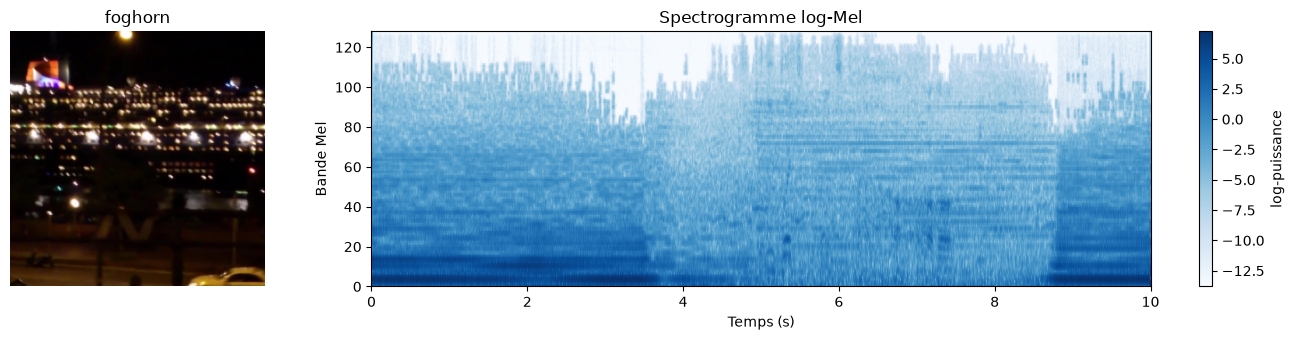

In [49]:
# Vérification sur un clip de validation : image centrale (une des 10 que voit le modèle) et
# spectrogramme log-Mel (calculé sur CPU).
# Rampe séquentielle à une seule teinte (Blues) : plus l'énergie de la bande est forte, plus c'est foncé.
sample_images, sample_waveform, sample_label = val_dataset[0]
sample_image = sample_images[FRAMES_PER_CLIP // 2]              # image du milieu du clip
sample_logmel = LogMelSpectrogram()(sample_waveform.unsqueeze(0))[0, 0]
print(f"images {tuple(sample_images.shape)} {sample_images.dtype} | audio {tuple(sample_waveform.shape)} "
      f"{sample_waveform.dtype} | log-Mel {tuple(sample_logmel.shape)}, "
      f"de {sample_logmel.min():.1f} à {sample_logmel.max():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={"width_ratios": [1, 3]})
axes[0].imshow(sample_image.permute(1, 2, 0).numpy())
axes[0].set_title(CLASSES[sample_label])
axes[0].axis("off")

mel_plot = axes[1].imshow(sample_logmel.numpy(), origin="lower", aspect="auto", cmap="Blues",
                          extent=[0, CLIP_SECONDS, 0, N_MELS])
axes[1].set_xlabel("Temps (s)")
axes[1].set_ylabel("Bande Mel")
axes[1].set_title("Spectrogramme log-Mel")
fig.colorbar(mel_plot, ax=axes[1], label="log-puissance")
plt.tight_layout()
plt.show()

In [50]:
class AudioEncoderCNN(PretrainedResNetEncoder):
    # Encodeur audio : forme d'onde int16 (B, NUM_SAMPLES) -> features (B, embed_size).
    #
    # Spectrogramme log-Mel 128 bandes, bn0 et SpecAugment comme avant, puis tronc ResNet-18 ImageNet
    # à un canal et la même tête à skip connections longues que l'encodeur image.
    def __init__(self, embed_size, pretrained=True):
        super().__init__("resnet18", embed_size, pretrained)

        # Première convolution ramenée à 1 canal : poids (64, 3, 7, 7) -> (64, 1, 7, 7), moyenne des
        # filtres R, G et B (comme l'AST). Appliqué aussi avec pretrained=False, pour que la forme des
        # poids corresponde à celle des checkpoints.
        conv1 = self.stem[0]
        conv1.weight.data = conv1.weight.data.mean(dim=1, keepdim=True)
        conv1.in_channels = 1

        self.frontend = LogMelSpectrogram()

        # Normalisation par bande Mel : les bandes sont les "canaux" de cette BatchNorm2d
        # (voir forward pour la transposition). Couche from scratch, hors du tronc.
        self.bn0 = nn.BatchNorm2d(N_MELS)

        # SpecAugment, uniquement en entraînement. iid_masks=True : masques différents pour
        # chaque clip du batch. Masques de fréquence de 16 bandes au plus (8 sur 64 auparavant).
        self.spec_augment = nn.Sequential(
            torchaudio.transforms.FrequencyMasking(freq_mask_param=16, iid_masks=True),
            torchaudio.transforms.FrequencyMasking(freq_mask_param=16, iid_masks=True),
            torchaudio.transforms.TimeMasking(time_mask_param=64, iid_masks=True),
            torchaudio.transforms.TimeMasking(time_mask_param=64, iid_masks=True),
        )

    def forward(self, waveform):
        x = self.frontend(waveform)                                # (B, 1, N_MELS, T), fp32

        # (B, 1, M, T) -> (B, M, 1, T) : les bandes Mel deviennent les canaux de bn0
        x = self.bn0(x.transpose(1, 2)).transpose(1, 2)

        if self.training:
            x = self.spec_augment(x)

        return self.features(x)                                    # 128 x 1001 -> stem -> 32 x 251

# **Agrégation temporelle et fusion**

### Agrégation des images du clip

Les `B × T` images d'un batch (`T = 10`) passent dans l'encodeur image comme un seul batch d'images. En sortie, les features `(B × T, 512)` sont remises en forme `(B, 512, T)`, puis moyennées sur `T` : une feature image par clip, `(B, 512)`.

La moyenne est l'agrégation la plus simple : aucun paramètre ajouté, et l'ordre des images n'est pas pris en compte. La forme `(B, D, T)` est celle qu'attend une agrégation plus riche (convolution temporelle 1D, attention), qui pourra remplacer la moyenne sans toucher au reste.

La loss est calculée sur la feature agrégée : le gradient de chaque clip se répartit sur ses 10 images. L'encodeur image voit 10 fois plus d'images par époque qu'avant, mais des images très redondantes : sur la concaténation naïve, la similarité cosinus moyenne entre les features des images d'un même clip était de 0,79.

### Fusion

```
features image (512) ─> normalisation L2 ─┐
                                          ├─> modality dropout (entraînement) ─> concat (1024)
features audio (512) ─> normalisation L2 ─┘
  -> Dropout -> Linear (1024 -> 512) -> BatchNorm1d -> ReLU -> Dropout -> Linear (512 -> 309) -> logits
```

Le MLP est celui des versions précédentes. Une couche cachée plutôt qu'une tête linéaire : sur une concaténation, une tête linéaire calcule `W_img · f_img + W_audio · f_audio + b`, c'est-à-dire la **somme de deux classifieurs indépendants** ; les modalités n'interagissent jamais. La couche cachée permet des combinaisons (« bruit d'eau » + « image de cuisine » → robinet plutôt que cascade).

**Normalisation L2.** Chaque vecteur de features est divisé par sa norme, séparément pour l'image et pour l'audio : les deux modalités arrivent dans la tête avec une norme de 1, pour chaque clip. Les BatchNorm1d de fin d'encodeur égalisent déjà l'échelle *moyenne* des deux modalités sur le batch ; la normalisation L2 égalise en plus la norme *de chaque clip*. Une modalité ne peut plus peser davantage dans la tête par la seule amplitude de ses features. C'est utile ici : moyennées sur 10 images très corrélées, les features image ont une variance plus faible que les features audio, qui sortent directement d'une BatchNorm1d. La couche cachée de la tête est suivie d'une BatchNorm1d : la petite échelle des entrées (norme 1 pour 512 composantes) n'a pas besoin d'être compensée.

**Modality dropout** (Neverova et al., 2015, *ModDrop: Adaptive Multi-Modal Gesture Recognition*). Pendant l'entraînement, un seul tirage par clip :
- avec une probabilité `P_DROP_AUDIO` = 0,3, les features audio sont remplacées par des zéros : la tête doit classer le clip à partir de l'image seule ;
- avec une probabilité `P_DROP_IMAGE` = 0,1, ce sont les features image ;
- sinon (60 % des clips), les deux modalités sont gardées. Jamais les deux supprimées à la fois.

Sans modality dropout, la tête n'a aucune raison d'apprendre à lire l'image : l'audio suffit presque toujours. Sur un clip sans audio, la loss de fusion ne peut baisser que grâce à l'image. La tête apprend donc à exploiter les features image, et l'encodeur image reçoit de la fusion un gradient réel au lieu d'un gradient presque nul. L'asymétrie (0,3 contre 0,1) vise le déséquilibre : supprimer l'image apprend à la tête à s'en passer, l'inverse de l'effet recherché. Une faible probabilité la garde tout de même robuste aux images peu informatives (écran titre, source du son hors champ).

Les zéros remplacent les features *après* la normalisation L2 : le vecteur nul, de norme 0, ne peut pas être confondu avec une vraie feature (de norme 1). En évaluation, les deux modalités sont toujours présentes. Contrepartie : la BatchNorm1d de la couche cachée estime ses statistiques sur un mélange de clips complets et de clips à une seule modalité, alors qu'en évaluation tous les clips sont complets. Cela crée un léger décalage de variance entre entraînement et évaluation, de même nature que celui entre Dropout et BatchNorm (Li et al., CVPR 2019, *Understanding the Disharmony between Dropout and Batch Normalization*), déjà présent avec le dropout de la tête.

La normalisation des images (moyenne/écart-type ImageNet) est faite dans le modèle, sur GPU, sur les uint8 reçus du DataLoader.

### Têtes auxiliaires et poids des losses

Les têtes auxiliaires sont inchangées : une couche linéaire (512 → 309) par encodeur, sur ses features **avant** normalisation L2 et modality dropout (pour l'image : la feature moyennée sur les T images). Elles ne servent qu'à l'entraînement et au diagnostic, pas à la prédiction finale. Seuls les poids de leurs losses changent :

$$\mathcal{L} = \mathcal{L}_{\text{fusion}} + \lambda_{\text{image}} \, \mathcal{L}_{\text{image}} + \lambda_{\text{audio}} \, \mathcal{L}_{\text{audio}}, \qquad \lambda_{\text{image}} = 1{,}5, \quad \lambda_{\text{audio}} = 0{,}5$$

Avec AdamW, qui normalise l'amplitude du gradient paramètre par paramètre, ce qui compte pour un encodeur est la part de chaque loss dans son gradient : celui de la fusion d'un côté, celui de sa tête auxiliaire de l'autre.
- **λ_image = 1,5** : l'erreur de la tête image seule pèse plus lourd que celle de la fusion. L'encodeur image est d'abord entraîné à classer seul.
- **λ_audio = 0,5** : l'encodeur audio apprend déjà vite grâce à la loss de fusion. Un poids réduit limite le signal supplémentaire qu'il reçoit de sa tête.
- **Même somme** que dans la version précédente (1,5 + 0,5 = 1 + 1) : seule la répartition entre modalités change, pas le poids total des losses auxiliaires face à celle de la fusion.

Les trois têtes utilisent la même loss : label smoothing et logit adjustment (cellule *Hyperparamètres*).

In [51]:
class ClassificationHead(nn.Module):
    # Tête de fusion : normalisation L2 de chaque modalité, modality dropout (entraînement seulement),
    # concaténation, puis MLP à une couche cachée.
    # Dropout en entrée : empêche la tête de s'appuyer sur quelques features isolées (d'une
    # seule modalité en particulier). Dropout avant la couche de sortie : régularise la
    # dernière couche, la plus exposée au sur-apprentissage.
    # bias=False sur la couche cachée, suivie d'une BatchNorm1d (biais redondant).
    def __init__(self, embed_size, hidden_size, num_classes, dropout, p_drop_image, p_drop_audio):
        super().__init__()
        assert p_drop_image + p_drop_audio <= 1, "un clip ne peut pas perdre ses deux modalités"
        self.p_drop_image = p_drop_image
        self.p_drop_audio = p_drop_audio
        self.net = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(2 * embed_size, hidden_size, bias=False),
            nn.BatchNorm1d(hidden_size),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes),
        )

    def modality_dropout(self, image_features, audio_features):
        # Un seul tirage u par clip : u < p_audio -> audio supprimé ; p_audio <= u < p_audio + p_image
        # -> image supprimée ; sinon les deux sont gardées. Supprimer = remplacer par des zéros.
        u = torch.rand(image_features.size(0), 1, device=image_features.device)
        drop_audio = u < self.p_drop_audio
        drop_image = (u >= self.p_drop_audio) & (u < self.p_drop_audio + self.p_drop_image)
        return image_features.masked_fill(drop_image, 0), audio_features.masked_fill(drop_audio, 0)

    def forward(self, image_features, audio_features):
        # Normalisation L2, séparément pour chaque modalité, en fp32 (norme sur 512 composantes).
        # Un vecteur nul (modalité masquée par evaluate) reste nul.
        image_features = F.normalize(image_features.float(), dim=1)
        audio_features = F.normalize(audio_features.float(), dim=1)
        if self.training:
            image_features, audio_features = self.modality_dropout(image_features, audio_features)
        return self.net(torch.cat([image_features, audio_features], dim=1))


class MultimodalClassifier(nn.Module):
    # Modèle complet : images uint8 (B, T, 3, 224, 224) + formes d'onde int16 (B, NUM_SAMPLES)
    # -> logits (B, num_classes) de la fusion, de la tête image seule et de la tête audio seule.
    #
    # forward sert à l'entraînement (les trois losses). encode et classify sont exposées séparément
    # pour l'évaluation (evaluate), qui ré-applique la tête de fusion sur des features permutées ou
    # masquées sans relancer les encodeurs. La prédiction n'utilise que la tête de fusion.
    # pretrained=False : encodeurs aux poids aléatoires, pour charger ensuite un checkpoint.
    def __init__(self, num_classes, embed_size=512, hidden_size=512, dropout=0.3,
                 p_drop_image=0.1, p_drop_audio=0.3, pretrained=True):
        super().__init__()
        # Moyenne et écart-type ImageNet à l'échelle [0, 255] : les images arrivent en uint8.
        # persistent=False : constantes, inutile de les stocker dans les checkpoints.
        self.register_buffer("image_mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1) * 255, persistent=False)
        self.register_buffer("image_std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1) * 255, persistent=False)

        self.image_encoder = ImageEncoderCNN(embed_size, pretrained)
        self.audio_encoder = AudioEncoderCNN(embed_size, pretrained)
        self.head = ClassificationHead(embed_size, hidden_size, num_classes, dropout, p_drop_image, p_drop_audio)
        # Têtes auxiliaires (voir la cellule markdown) : un classifieur linéaire par encodeur, sur ses
        # seules features. Elles ne servent qu'à l'entraînement et au diagnostic.
        self.image_aux_head = nn.Linear(embed_size, num_classes)
        self.audio_aux_head = nn.Linear(embed_size, num_classes)

    def encode(self, images, waveforms):
        # images (B, T, 3, H, W) uint8, waveforms (B, NUM_SAMPLES) int16 -> features (B, E) de chaque
        # modalité, celles de l'image agrégées sur les T images du clip.
        batch_size, n_frames = images.shape[:2]
        # (B, T, 3, H, W) -> (B x T, 3, H, W) : les images de tous les clips forment un seul batch
        # pour l'encodeur 2D. channels_last appliqué aux uint8 (4x moins d'octets à réorganiser
        # qu'en float32) ; la normalisation en float conserve ce format.
        images = images.flatten(0, 1).contiguous(memory_format=torch.channels_last)
        images = (images.float() - self.image_mean) / self.image_std
        frame_features = self.image_encoder(images)                          # (B x T, E)
        # Reshape en (B, E, T) : une colonne de features par image, dans l'ordre temporel
        frame_features = frame_features.unflatten(0, (batch_size, n_frames)).transpose(1, 2)
        image_features = frame_features.mean(dim=2)                          # moyenne sur T : (B, E)
        return image_features, self.audio_encoder(waveforms)

    def classify(self, image_features, audio_features):
        # Fusion : normalisation L2, modality dropout (entraînement), concaténation, MLP
        return self.head(image_features, audio_features)

    def forward(self, images, waveforms):
        image_features, audio_features = self.encode(images, waveforms)
        return (self.classify(image_features, audio_features),
                self.image_aux_head(image_features), self.audio_aux_head(audio_features))

# **Métriques**

- **Top-k accuracy** (k = 1 et 5) : proportion de clips dont la vraie classe est parmi les k classes les plus probables. Le top-5 est informatif sur VGGSound, où beaucoup de classes sont proches (`playing electric guitar` / `playing bass guitar`, `dog barking` / `dog growling`…).
- **Macro-F1** : moyenne des F1 par classe, chaque classe pesant autant. C'est le **critère de sélection du meilleur modèle** : le jeu de test est équilibré (~50 clips par classe) alors que val reproduit le déséquilibre de train (7 à 51 clips par classe). Sur val, l'accuracy et le weighted-F1 favorisent les classes fréquentes ; le macro-F1 mesure ce qui compte sur test.
- **Weighted-F1** : moyenne des F1 par classe pondérée par l'effectif de chaque classe. Il reflète la performance « telle que vécue » sur la distribution de val. Sur test, équilibré, il est quasiment égal au macro-F1.
- **Têtes unimodales** : top-1 et macro-F1 des têtes auxiliaires image et audio (cellule *Fusion*), c'est-à-dire ce que chaque encodeur sait faire seul, suivis à chaque époque.

Les métriques sont calculées sur GPU à partir de la matrice de confusion, en un seul passage. L'implémentation a été vérifiée identique à scikit-learn (`f1_score(average="macro" / "weighted", zero_division=0)` et `top_k_accuracy_score`), y compris quand certaines classes sont absentes des prédictions.

**Diagnostic d'équilibre des modalités.** Pour chaque batch, la tête de fusion est ré-appliquée sur des features modifiées :
- **modalité mélangée** : les features d'une modalité sont permutées entre les clips du batch, l'autre restant intacte. La correspondance image/son est cassée, mais la distribution des features ne change pas. La chute de top-1 mesure à quel point la tête **s'appuie** sur la modalité mélangée. `top-1 image mélangée` proche du top-1 complet → l'image ne sert presque à rien ; `top-1 audio mélangé` proche du hasard (1/309 ≈ 0,3 %) → tout repose sur l'audio. Mesure comparable avec les versions précédentes.
- **modalité masquée** (nouveau) : les features d'une modalité sont remplacées par des zéros, exactement comme le fait le modality dropout pendant l'entraînement. Le `top-1 audio masqué` mesure ce que la tête de fusion **sait faire** de l'image seule, et le `top-1 image masquée` ce qu'elle sait faire de l'audio seul. Dans les versions précédentes, une mise à zéro était hors distribution pour la tête, d'où le seul mélange. La tête a maintenant appris à classer des clips sans audio (30 % des clips d'entraînement) ou sans image (10 %).

Les encodeurs ne tournent qu'une fois par batch ; seule la tête (négligeable) est appliquée cinq fois.

**Toutes les images du clip en évaluation.** Comme à l'entraînement, chaque clip est vu à travers ses 10 images, agrégées dans le modèle par la moyenne de leurs features. Les versions précédentes, entraînées sur une image à la fois, moyennaient en évaluation les probabilités prédites pour 3 images (1, 5 et 8). Pas d'augmentation en évaluation : la prédiction est déterministe.

In [52]:
def compute_metrics(logits, targets, num_classes, topk=(1, 5)):
    # logits (N, C), targets (N,) -> dict : top{k}, macro_f1, weighted_f1, per_class_f1 (tenseur CPU).
    logits, targets = logits.float(), targets.long()
    metrics = {}

    # Top-k accuracy : un seul topk() pour le plus grand k, les plus petits en sont des préfixes
    top_predictions = logits.topk(max(topk), dim=1).indices              # (N, k_max), triés
    hits = top_predictions == targets[:, None]
    for k in topk:
        metrics[f"top{k}"] = hits[:, :k].any(dim=1).float().mean().item()

    # Matrice de confusion C x C (ligne = vraie classe, colonne = classe prédite) en un bincount
    predictions = top_predictions[:, 0]
    confusion = torch.bincount(targets * num_classes + predictions,
                               minlength=num_classes ** 2).reshape(num_classes, num_classes)
    true_positives = confusion.diag().float()
    support = confusion.sum(dim=1).float()                               # TP + FN : effectif réel
    predicted = confusion.sum(dim=0).float()                             # TP + FP : nombre de prédictions

    # F1 = 2 TP / (2 TP + FP + FN) = 2 TP / (support + predicted). Une classe ni présente ni
    # prédite (dénominateur nul) est exclue de la moyenne macro, comme dans scikit-learn ; une
    # classe présente mais jamais prédite (ou l'inverse) compte pour F1 = 0.
    denominator = support + predicted
    f1 = torch.where(denominator > 0, 2 * true_positives / denominator.clamp_min(1), torch.zeros_like(true_positives))
    metrics["macro_f1"] = f1[denominator > 0].mean().item()
    metrics["weighted_f1"] = ((f1 * support).sum() / support.sum()).item()
    metrics["per_class_f1"] = f1.cpu()
    return metrics


@torch.no_grad()
def evaluate(model, loader, seed=0, return_logits=False):
    # Évalue le modèle sur tout le loader. Renvoie les métriques du modèle complet, la loss
    # (entropie croisée standard, sans label smoothing ni logit adjustment, pour rester
    # comparable entre runs), le top-1 / macro-F1 avec chaque modalité mélangée ou masquée, et
    # ceux de chaque tête auxiliaire (ce que chaque encodeur sait faire seul).
    # return_logits=True : ajoute les logits du modèle complet (N, C), sur CPU, dans l'ordre du
    # loader, pour des métriques calculées après coup (cellule "Test corrigé").
    model.eval()
    # Générateur dédié : permutations identiques d'une époque à l'autre, sans toucher à
    # l'aléa global (ordre des batchs, augmentations).
    generator = torch.Generator(device=device).manual_seed(seed)
    all_logits = {name: [] for name in ("full", "image_shuffled", "audio_shuffled", "image_masked",
                                        "audio_masked", "image_head", "audio_head")}
    all_targets = []

    for images, waveforms, labels in loader:
        images, waveforms, labels = to_device(images, waveforms, labels)
        # Évaluation en bf16, comme l'entraînement. Contrairement au fp16 (val loss NaN de la v6
        # du captioning), le bf16 a la même plage d'exposant que le fp32 : les activations
        # amplifiées par la BatchNorm en mode eval ne peuvent pas dépasser la valeur maximale.
        with torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            # (B, E) chacune ; les features image sont déjà moyennées sur les T images du clip
            image_features, audio_features = model.encode(images, waveforms)
            permutation = torch.randperm(labels.size(0), device=device, generator=generator)
            all_logits["full"].append(model.classify(image_features, audio_features))
            all_logits["image_shuffled"].append(model.classify(image_features[permutation], audio_features))
            all_logits["audio_shuffled"].append(model.classify(image_features, audio_features[permutation]))
            # Modalité masquée : features nulles, comme le modality dropout de l'entraînement
            all_logits["image_masked"].append(model.classify(torch.zeros_like(image_features), audio_features))
            all_logits["audio_masked"].append(model.classify(image_features, torch.zeros_like(audio_features)))
            all_logits["image_head"].append(model.image_aux_head(image_features))
            all_logits["audio_head"].append(model.audio_aux_head(audio_features))
        all_targets.append(labels)

    targets = torch.cat(all_targets)
    logits = {name: torch.cat(chunks).float() for name, chunks in all_logits.items()}

    metrics = compute_metrics(logits["full"], targets, NUM_CLASSES, topk=(1, 5))
    metrics["loss"] = F.cross_entropy(logits["full"], targets).item()
    for name in ("image_shuffled", "audio_shuffled", "image_masked", "audio_masked", "image_head", "audio_head"):
        partial = compute_metrics(logits[name], targets, NUM_CLASSES, topk=(1,))
        metrics[f"top1_{name}"] = partial["top1"]
        metrics[f"macro_f1_{name}"] = partial["macro_f1"]
    if return_logits:
        metrics["logits"] = logits["full"].cpu()
    return metrics

# **Hyperparamètres et optimisations GPU**

### Choix des hyperparamètres

Inchangés par rapport à la version précédente, sauf les learning rates (un par groupe de paramètres), le warmup, l'époque de gel et le nombre d'époques.

| Hyperparamètre | Valeur | Justification |
|---|---|---|
| Taille de batch | 256 clips par pas d'optimisation, en 8 micro-batchs de 32 clips (accumulation de gradient) | Inchangée : 681 pas par époque. Un micro-batch de 32 clips prend ~6 Go de VRAM en fine-tuning, 4,8 Go troncs gelés (mesuré). |
| Optimiseur | AdamW (`fused=True`), 6 groupes de paramètres | (couches from scratch, tronc image, tronc audio) × (avec, sans weight decay). |
| Learning rate max | couches from scratch : 1e-3 ; tronc image : 1e-4 (×0,1) ; tronc audio : 3e-4 (×0,3) | Les couches from scratch (têtes des encodeurs, `bn0`, tête de fusion, têtes auxiliaires) gardent le learning rate des versions précédentes. Avec 1e-3, AdamW déplacerait chaque poids pré-entraîné de jusqu'à 1e-3 par pas, alors que ces poids valent quelques 1e-2 : en quelques centaines de pas, les features d'ImageNet seraient écrasées. ×0,1 est le rapport habituel en fine-tuning. Le tronc audio reçoit ×0,3 : l'écart de domaine (spectrogrammes contre photos) est plus grand, seuls les filtres de bas niveau se transfèrent vraiment, et le tronc doit davantage s'adapter. Mise à l'échelle en racine carrée de `BATCH_SIZE / 256`, comme avant. |
| Gel des troncs | 1re époque (681 pas) | Au départ, la tête de fusion et les têtes des encodeurs sont aléatoires. Les premiers gradients qui redescendent dans les troncs ne portent pas d'information utile et déforment les features pré-entraînées (Kumar et al., ICLR 2022, *Fine-Tuning can Distort Pretrained Features and Underperform Out-of-Distribution* : entraîner d'abord la tête seule, puis tout le réseau). Pendant cette époque, seules les couches from scratch apprennent. Les BatchNorm des troncs restent en mode entraînement : leurs statistiques s'adaptent aux images de VGGSound et surtout aux spectrogrammes, très différents des photos. L'époque est aussi plus rapide : pas de backward à travers le tronc image. |
| Warmup | couches from scratch : 1 époque (l'époque de gel) ; troncs : 1 époque après le dégel | Linéaire dans les deux cas. Au dégel, les moments d'Adam des troncs partent de zéro : sans warmup, leurs premiers pas seraient de la taille maximale. |
| Décroissance | cosinus jusqu'à 1e-6 après le warmup des couches from scratch, mise à jour à chaque pas | Inchangée. Les troncs suivent le même cosinus, multiplié par leur facteur. |
| Époques | 1 (gel) + 10 (fine-tuning) | Des encodeurs pré-entraînés convergent plus vite qu'un entraînement from scratch. Changer `FINETUNE_EPOCHS` modifie la forme du cosinus : à décider avant l'entraînement. |
| Weight decay | 0,05, hors BatchNorm et biais | Inchangé. Découplé (AdamW) : proportionnel au learning rate, donc 10x plus faible sur le tronc image, qui ne rétrécit que de quelques pourcents sur tout l'entraînement. |
| Label smoothing | 0,1 | Inchangé. |
| Logit adjustment | τ = 1 | Inchangé. |
| Dropout de la tête | 0,3 | Inchangé. |
| Modality dropout | audio 0,3, image 0,1 | Inchangé. |
| Poids des losses auxiliaires | λ_image = 1,5, λ_audio = 0,5 | Inchangés. |
| Clipping du gradient | norme 5 | Inchangé, sur tous les paramètres. |
| Augmentations | image : crop aléatoire (70-100 %), flip, jitter de couleur, tirés une fois par clip ; audio : SpecAugment (masques de fréquence ≤ 16 bandes sur 128) | Inchangées. Toujours utiles en fine-tuning : 174 k clips pour 33 M de paramètres. |

### Optimisations pour la RTX 5060 Ti (16 Go, Blackwell)

Inchangées : précision mixte bf16, channels_last, TF32, `cudnn.benchmark`, AdamW `fused=True`, accumulation de gradient, pré-traitements sur GPU, décodage JPEG à résolution réduite, `pin_memory` + `non_blocking`, pas de `.item()` à chaque pas, `torch.compile` (`USE_COMPILE`).

- **Troncs gelés** : `requires_grad=False` sur leurs paramètres. Aucun gradient n'est calculé pour eux, et rien n'est stocké pour le backward du tronc image : son entrée ne demande pas de gradient. Le backward traverse toujours le tronc audio, pour atteindre `bn0`, qui apprend. Au dégel, `torch.compile` recompile une fois le modèle.
- **Débit mesuré** : ~102 clips/s en fine-tuning (GPU saturé), soit ~29 min par époque. Troncs gelés, le GPU dépasse 220 clips/s : c'est alors le DataLoader (~175 clips/s) qui limite, soit ~17 min. Évaluation : ~260 clips/s, pic de VRAM de 6,8 Go à 64 clips par batch.

# **Initialisation/Reprise**

In [53]:
# --- Hyperparamètres du modèle ---
EMBED_SIZE = 512                      # dimension des features de CHAQUE encodeur (concaténation : 1024)
HEAD_HIDDEN_SIZE = 512
HEAD_DROPOUT = 0.3
P_DROP_AUDIO = 0.3                    # modality dropout : part des clips d'entraînement sans audio
P_DROP_IMAGE = 0.1                    # ... et sans image (jamais les deux à la fois)

# --- Hyperparamètres d'optimisation (justifiés dans la cellule précédente) ---
FREEZE_EPOCHS = 1                     # époques avec les troncs pré-entraînés gelés
FINETUNE_EPOCHS = 10                  # époques de fine-tuning de tout le modèle
NUM_EPOCHS = FREEZE_EPOCHS + FINETUNE_EPOCHS
WARMUP_EPOCHS = 1                     # warmup des couches from scratch (pendant l'époque de gel)
BACKBONE_WARMUP_EPOCHS = 1            # warmup des troncs, à partir du dégel
BASE_LR = 1e-3                        # learning rate max des couches from scratch pour BASE_BATCH_SIZE
BASE_BATCH_SIZE = 256
PEAK_LR = BASE_LR * (BATCH_SIZE / BASE_BATCH_SIZE) ** 0.5   # BATCH_SIZE : clips par pas (accumulés)
BACKBONE_LR_SCALE = {"image": 0.1, "audio": 0.3}            # learning rate des troncs, relatif à PEAK_LR
MIN_LR = 1e-6                         # learning rate en fin de cosinus (couches from scratch)
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
LOGIT_ADJUST_TAU = 1.0                # 0 pour désactiver la correction du déséquilibre des classes
GRAD_CLIP_NORM = 5.0
LAMBDA_IMAGE = 1.5                    # L = L_fusion + λ_image L_image + λ_audio L_audio
LAMBDA_AUDIO = 0.5

# --- Précision mixte et compilation ---
USE_AMP = device.type == "cuda"
AMP_DTYPE = torch.bfloat16
USE_COMPILE = True                  # nécessite python3.14-dev (voir la cellule précédente)
                                    # ne l'activer que pour un entraînement complet, et le désactiver pour le debugging

# --- Fichiers ---
# Noms propres à ce run (RUN_TAG) : un futur notebook dans le même dossier n'écrasera pas ces
# sauvegardes. Le checkpoint de reprise contient aussi l'optimiseur et l'historique ; le
# meilleur modèle (macro-F1 de validation) ne contient que les poids.
CHECKPOINT_DIR = "checkpoints"
RUN_TAG = "pretrained"
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, f"checkpoint_{RUN_TAG}.pth")
BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, f"best_macro_f1_{RUN_TAG}.pth")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

MODEL_CONFIG = dict(
    num_classes=NUM_CLASSES, embed_size=EMBED_SIZE, hidden_size=HEAD_HIDDEN_SIZE, dropout=HEAD_DROPOUT,
    p_drop_image=P_DROP_IMAGE, p_drop_audio=P_DROP_AUDIO,
)

# 1. Modèle, troncs initialisés avec les poids ImageNet
# .to(device, memory_format=torch.channels_last) : poids des convolutions au format NHWC des
# tensor cores. Sans effet sur les résultats, seulement sur la vitesse.
model = MultimodalClassifier(**MODEL_CONFIG).to(device, memory_format=torch.channels_last)

def n_params(module):
    return sum(p.numel() for p in module.parameters()) / 1e6


backbone_params = {
    "image": list(model.image_encoder.backbone_parameters()),
    "audio": list(model.audio_encoder.backbone_parameters()),
}
backbone_ids = {id(p) for params in backbone_params.values() for p in params}
scratch_params = [p for p in model.parameters() if id(p) not in backbone_ids]

print(f"Paramètres : {n_params(model):.1f} M (encodeur image {n_params(model.image_encoder):.1f} M, "
      f"encodeur audio {n_params(model.audio_encoder):.1f} M, tête {n_params(model.head):.2f} M, "
      f"têtes auxiliaires {n_params(model.image_aux_head) + n_params(model.audio_aux_head):.2f} M)")
print(f"  dont pré-entraînés : tronc image {sum(p.numel() for p in backbone_params['image']) / 1e6:.1f} M, "
      f"tronc audio {sum(p.numel() for p in backbone_params['audio']) / 1e6:.1f} M ; "
      f"from scratch : {sum(p.numel() for p in scratch_params) / 1e6:.1f} M")

# Modèle utilisé pour le forward d'entraînement. Il partage ses poids avec `model` : les
# sauvegardes et l'évaluation passent par `model` (pas de préfixe "_orig_mod." dans les clés).
train_forward = torch.compile(model) if USE_COMPILE else model

# 2. Optimiseur : AdamW, un groupe par (couches from scratch, tronc image, tronc audio) x (avec,
# sans weight decay). Weight decay uniquement sur les poids des convolutions et des couches
# linéaires (tenseurs à >= 2 dimensions) ; ni sur les BatchNorm ni sur les biais (1 dimension).
# "name" identifie le groupe pour lr_at_group.
param_groups = []
for name, params in (("scratch", scratch_params), ("image", backbone_params["image"]),
                     ("audio", backbone_params["audio"])):
    param_groups.append({"params": [p for p in params if p.ndim >= 2], "weight_decay": WEIGHT_DECAY, "name": name})
    param_groups.append({"params": [p for p in params if p.ndim < 2], "weight_decay": 0.0, "name": name})
optimizer = torch.optim.AdamW(param_groups, lr=PEAK_LR, fused=device.type == "cuda")
print(f"Learning rate max : {PEAK_LR:.2e} pour les couches from scratch, "
      f"{PEAK_LR * BACKBONE_LR_SCALE['image']:.2e} pour le tronc image, "
      f"{PEAK_LR * BACKBONE_LR_SCALE['audio']:.2e} pour le tronc audio "
      f"(BATCH_SIZE={BATCH_SIZE} clips par pas, {ACCUM_STEPS} micro-batchs de {MICRO_BATCH_SIZE})")

# 3. Learning rate : warmup linéaire puis cosinus, calculé à chaque pas à partir du numéro de pas
# global. Pas d'objet scheduler à sauvegarder : à la reprise, le learning rate se déduit
# directement de l'époque de départ, même après une interruption au milieu d'une époque.
# Un pas = un pas d'optimisation (ACCUM_STEPS micro-batchs), pas un micro-batch.
steps_per_epoch = len(train_loader) // ACCUM_STEPS
total_steps = NUM_EPOCHS * steps_per_epoch
warmup_steps = WARMUP_EPOCHS * steps_per_epoch
freeze_steps = FREEZE_EPOCHS * steps_per_epoch
backbone_warmup_steps = BACKBONE_WARMUP_EPOCHS * steps_per_epoch


def lr_at(step):
    # Learning rate des couches from scratch
    if step < warmup_steps:
        return PEAK_LR * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return MIN_LR + 0.5 * (PEAK_LR - MIN_LR) * (1 + math.cos(math.pi * progress))


def lr_at_group(name, step):
    # Troncs : même cosinus multiplié par BACKBONE_LR_SCALE, nul pendant le gel, puis rampe
    # linéaire sur backbone_warmup_steps à partir du dégel.
    if name == "scratch":
        return lr_at(step)
    ramp = min(1.0, max(0, step - freeze_steps + 1) / backbone_warmup_steps)
    return lr_at(step) * BACKBONE_LR_SCALE[name] * ramp


def set_backbones_trainable(trainable):
    # Gel / dégel des troncs pré-entraînés. Gelés, leurs paramètres n'ont pas de gradient
    # (grad = None) : AdamW les ignore, weight decay compris, et clip_grad_norm_ aussi.
    for params in backbone_params.values():
        for p in params:
            p.requires_grad_(trainable)


# 4. Loss : entropie croisée avec label smoothing. Le logit adjustment ajoute
# LOGIT_ADJUST_TAU * log(prior) aux logits avant la loss (boucle d'apprentissage).
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
log_class_prior = torch.log(train_class_counts.float() / train_class_counts.sum()).to(device)

# 5. GradScaler : utile seulement en fp16 (en bf16, aucun gradient ne sous-déborde). Désactivé,
# ses appels dans la boucle d'apprentissage deviennent transparents.
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)

# 6. État
HISTORY_KEYS = ("train_loss", "train_top1", "val_loss", "val_top1", "val_top5", "val_macro_f1",
                "val_weighted_f1", "val_top1_image_shuffled", "val_top1_audio_shuffled",
                "val_top1_image_masked", "val_top1_audio_masked",
                "train_loss_image_head", "train_loss_audio_head", "val_top1_image_head", "val_top1_audio_head")
history = {key: [] for key in HISTORY_KEYS}

if os.path.exists(CHECKPOINT_PATH):
    print("Chargement du checkpoint trouvé...")
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    history = checkpoint["history"]

    print(f"Reprise de l'entraînement à l'époque {checkpoint['epoch'] + 2}/{NUM_EPOCHS}")
else:
    print("Aucun checkpoint trouvé. Démarrage depuis les poids ImageNet.")

Paramètres : 34.4 M (encodeur image 21.8 M, encodeur audio 11.7 M, tête 0.68 M, têtes auxiliaires 0.32 M)
  dont pré-entraînés : tronc image 21.3 M, tronc audio 11.2 M ; from scratch : 2.0 M
Learning rate max : 1.00e-03 pour les couches from scratch, 1.00e-04 pour le tronc image, 3.00e-04 pour le tronc audio (BATCH_SIZE=256 clips par pas, 8 micro-batchs de 32)
Chargement du checkpoint trouvé...
Reprise de l'entraînement à l'époque 4/11


# **Apprentissage**

In [54]:
LOG_EVERY = 25          # en pas d'optimisation (25 x 256 clips, ~1 min)


def save_atomic(obj, path):
    # Écriture dans un fichier temporaire puis renommage : un Ctrl+C pendant torch.save (le
    # checkpoint pèse ~400 Mo) ne peut pas laisser un checkpoint tronqué à la place du précédent.
    tmp_path = path + ".tmp"
    torch.save(obj, tmp_path)
    os.replace(tmp_path, path)


# Point de départ = nombre d'époques terminées dans l'historique (mis à jour seulement en fin
# d'époque). Relancer cette cellule après une interruption, sans repasser par
# "Initialisation/Reprise", reprend donc l'époque interrompue, avec le bon learning rate.
start_epoch = len(history["train_loss"])
for values in history.values():
    del values[start_epoch:]

best_macro_f1 = max(history["val_macro_f1"], default=float("-inf"))

for epoch in range(start_epoch, NUM_EPOCHS):

    # Pic de VRAM de CETTE époque (sinon max_memory_allocated renvoie le maximum depuis le
    # début du process)
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)

    # Troncs gelés pendant les FREEZE_EPOCHS premières époques (cellule "Hyperparamètres") : seules
    # les couches from scratch apprennent. Les BatchNorm des troncs restent en mode train et adaptent
    # leurs statistiques aux données de VGGSound.
    frozen = epoch < FREEZE_EPOCHS
    set_backbones_trainable(not frozen)

    # ---------- TRAIN ----------
    model.train()
    t0 = time.time()
    # Accumulateurs sur GPU : pas de synchronisation CPU-GPU à chaque batch. running_loss garde
    # les trois losses séparément : fusion, tête image, tête audio.
    running_loss = torch.zeros(3, device=device)
    running_correct = torch.zeros((), device=device, dtype=torch.long)
    seen = 0
    # Remise à zéro en début d'époque : une époque interrompue au milieu d'une accumulation, puis
    # relancée, ne repart pas de gradients partiels.
    optimizer.zero_grad(set_to_none=True)

    for batch_idx, (images, waveforms, labels) in enumerate(train_loader):
        # Accumulation de gradient : ACCUM_STEPS micro-batchs de MICRO_BATCH_SIZE clips par pas
        # d'optimisation. Les derniers micro-batchs de l'époque, trop peu nombreux pour un pas
        # complet (au plus ACCUM_STEPS - 1, tirés au hasard à chaque époque), sont ignorés.
        step, micro_step = divmod(batch_idx, ACCUM_STEPS)
        if step == steps_per_epoch:
            break

        images, waveforms, labels = to_device(images, waveforms, labels)

        with torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            logits, image_logits, audio_logits = train_forward(images, waveforms)

        # Loss en fp32, hors autocast (log-softmax sur 309 classes). Logit adjustment : le
        # log-prior des classes est ajouté aux logits dans la loss seulement ; les logits
        # bruts, utilisés en prédiction, n'encodent ainsi plus la fréquence des classes de train.
        # Même loss (label smoothing + logit adjustment) pour les trois têtes.
        logits = logits.float()
        adjustment = LOGIT_ADJUST_TAU * log_class_prior
        losses = torch.stack([
            criterion(logits + adjustment, labels),                      # fusion
            criterion(image_logits.float() + adjustment, labels),        # tête image seule
            criterion(audio_logits.float() + adjustment, labels),        # tête audio seule
        ])
        loss = losses[0] + LAMBDA_IMAGE * losses[1] + LAMBDA_AUDIO * losses[2]
        # Division par ACCUM_STEPS : le gradient accumulé est celui de la loss moyenne sur les
        # BATCH_SIZE clips du pas, comme avec un seul batch de BATCH_SIZE clips.
        scaler.scale(loss / ACCUM_STEPS).backward()

        # Loss et top-1 d'entraînement de la fusion : mesurés avec modality dropout et dropout
        running_loss += losses.detach() * labels.size(0)
        running_correct += (logits.argmax(dim=1) == labels).sum()
        seen += labels.size(0)

        if micro_step < ACCUM_STEPS - 1:
            continue

        # Pas d'optimisation, une fois les ACCUM_STEPS micro-batchs accumulés. Un learning rate par
        # groupe : couches from scratch, tronc image, tronc audio (lr_at_group).
        global_step = epoch * steps_per_epoch + step
        lr = lr_at(global_step)
        for group in optimizer.param_groups:
            group["lr"] = lr_at_group(group["name"], global_step)
        scaler.unscale_(optimizer)                     # gradients à leur vraie échelle avant le clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)

        if (step + 1) % LOG_EVERY == 0:
            elapsed = time.time() - t0
            loss_fusion, loss_image, loss_audio = (running_loss / seen).tolist()
            print(f"  [epoch {epoch+1}] pas {step+1}/{steps_per_epoch} "
                  f"- loss {loss_fusion:.4f} (image {loss_image:.4f}, audio {loss_audio:.4f}) "
                  f"- top-1 {running_correct.item()/seen:.3f} "
                  f"- lr {lr:.2e} " + ("(troncs gelés) " if frozen else
                  f"(troncs image {lr_at_group('image', global_step):.2e}, audio {lr_at_group('audio', global_step):.2e}) ")
                  + f"- {seen/elapsed:.0f} clips/s - {elapsed:.0f}s", flush=True)

    # train_loss : loss de la fusion seule, comparable à celle des versions précédentes
    train_loss, train_loss_image, train_loss_audio = (running_loss / seen).tolist()
    train_top1 = running_correct.item() / seen

    # ---------- VALIDATION ----------
    val = evaluate(model, val_loader)

    history["train_loss"].append(train_loss)
    history["train_top1"].append(train_top1)
    history["val_loss"].append(val["loss"])
    history["val_top1"].append(val["top1"])
    history["val_top5"].append(val["top5"])
    history["val_macro_f1"].append(val["macro_f1"])
    history["val_weighted_f1"].append(val["weighted_f1"])
    history["val_top1_image_shuffled"].append(val["top1_image_shuffled"])
    history["val_top1_audio_shuffled"].append(val["top1_audio_shuffled"])
    history["val_top1_image_masked"].append(val["top1_image_masked"])
    history["val_top1_audio_masked"].append(val["top1_audio_masked"])
    history["train_loss_image_head"].append(train_loss_image)
    history["train_loss_audio_head"].append(train_loss_audio)
    history["val_top1_image_head"].append(val["top1_image_head"])
    history["val_top1_audio_head"].append(val["top1_audio_head"])

    print(f"Epoch {epoch+1}/{NUM_EPOCHS}{' (troncs gelés)' if frozen else ''} - {time.time()-t0:.0f}s - lr {lr:.2e}")
    print(f"Train : loss {train_loss:.4f} (tête image {train_loss_image:.4f}, tête audio {train_loss_audio:.4f}) "
          f"| top-1 {train_top1:.4f}")
    print(f"Val   : loss {val['loss']:.4f} | top-1 {val['top1']:.4f} | top-5 {val['top5']:.4f} | "
          f"macro-F1 {val['macro_f1']:.4f} | weighted-F1 {val['weighted_f1']:.4f}")
    print(f"Modalités (val top-1) : image mélangée {val['top1_image_shuffled']:.4f} | "
          f"audio mélangé {val['top1_audio_shuffled']:.4f} | image masquée {val['top1_image_masked']:.4f} | "
          f"audio masqué {val['top1_audio_masked']:.4f}")
    print(f"Têtes unimodales (val top-1) : image {val['top1_image_head']:.4f} | audio {val['top1_audio_head']:.4f}")

    # Pic de VRAM de l'époque : sert à ajuster MICRO_BATCH_SIZE en visant ~80-90 % de la VRAM totale
    if device.type == "cuda":
        peak = torch.cuda.max_memory_allocated(device) / 1e9
        total = torch.cuda.get_device_properties(device).total_memory / 1e9
        print(f"VRAM pic époque : {peak:.2f} Go / {total:.1f} Go ({100*peak/total:.0f}%)")

    # ---------- SAVE ----------
    if val["macro_f1"] > best_macro_f1:
        best_macro_f1 = val["macro_f1"]
        save_atomic(model.state_dict(), BEST_MODEL_PATH)
        print("Sauvegarde du meilleur modèle (macro-F1 de validation)")

    save_atomic({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "model_config": MODEL_CONFIG,
    }, CHECKPOINT_PATH)

  [epoch 4] pas 25/681 - loss 2.0788 (image 2.2180, audio 2.2496) - top-1 0.666 - lr 9.01e-04 (troncs image 9.01e-05, audio 2.70e-04) - 91 clips/s - 70s
  [epoch 4] pas 50/681 - loss 2.0649 (image 2.1970, audio 2.2477) - top-1 0.670 - lr 8.98e-04 (troncs image 8.98e-05, audio 2.69e-04) - 96 clips/s - 134s
  [epoch 4] pas 75/681 - loss 2.0513 (image 2.1845, audio 2.2390) - top-1 0.673 - lr 8.94e-04 (troncs image 8.94e-05, audio 2.68e-04) - 98 clips/s - 196s
  [epoch 4] pas 100/681 - loss 2.0563 (image 2.1906, audio 2.2343) - top-1 0.672 - lr 8.91e-04 (troncs image 8.91e-05, audio 2.67e-04) - 99 clips/s - 258s
  [epoch 4] pas 125/681 - loss 2.0508 (image 2.1909, audio 2.2391) - top-1 0.674 - lr 8.87e-04 (troncs image 8.87e-05, audio 2.66e-04) - 99 clips/s - 323s
  [epoch 4] pas 150/681 - loss 2.0550 (image 2.1986, audio 2.2419) - top-1 0.673 - lr 8.83e-04 (troncs image 8.83e-05, audio 2.65e-04) - 100 clips/s - 386s
  [epoch 4] pas 175/681 - loss 2.0569 (image 2.2032, audio 2.2428) - top-

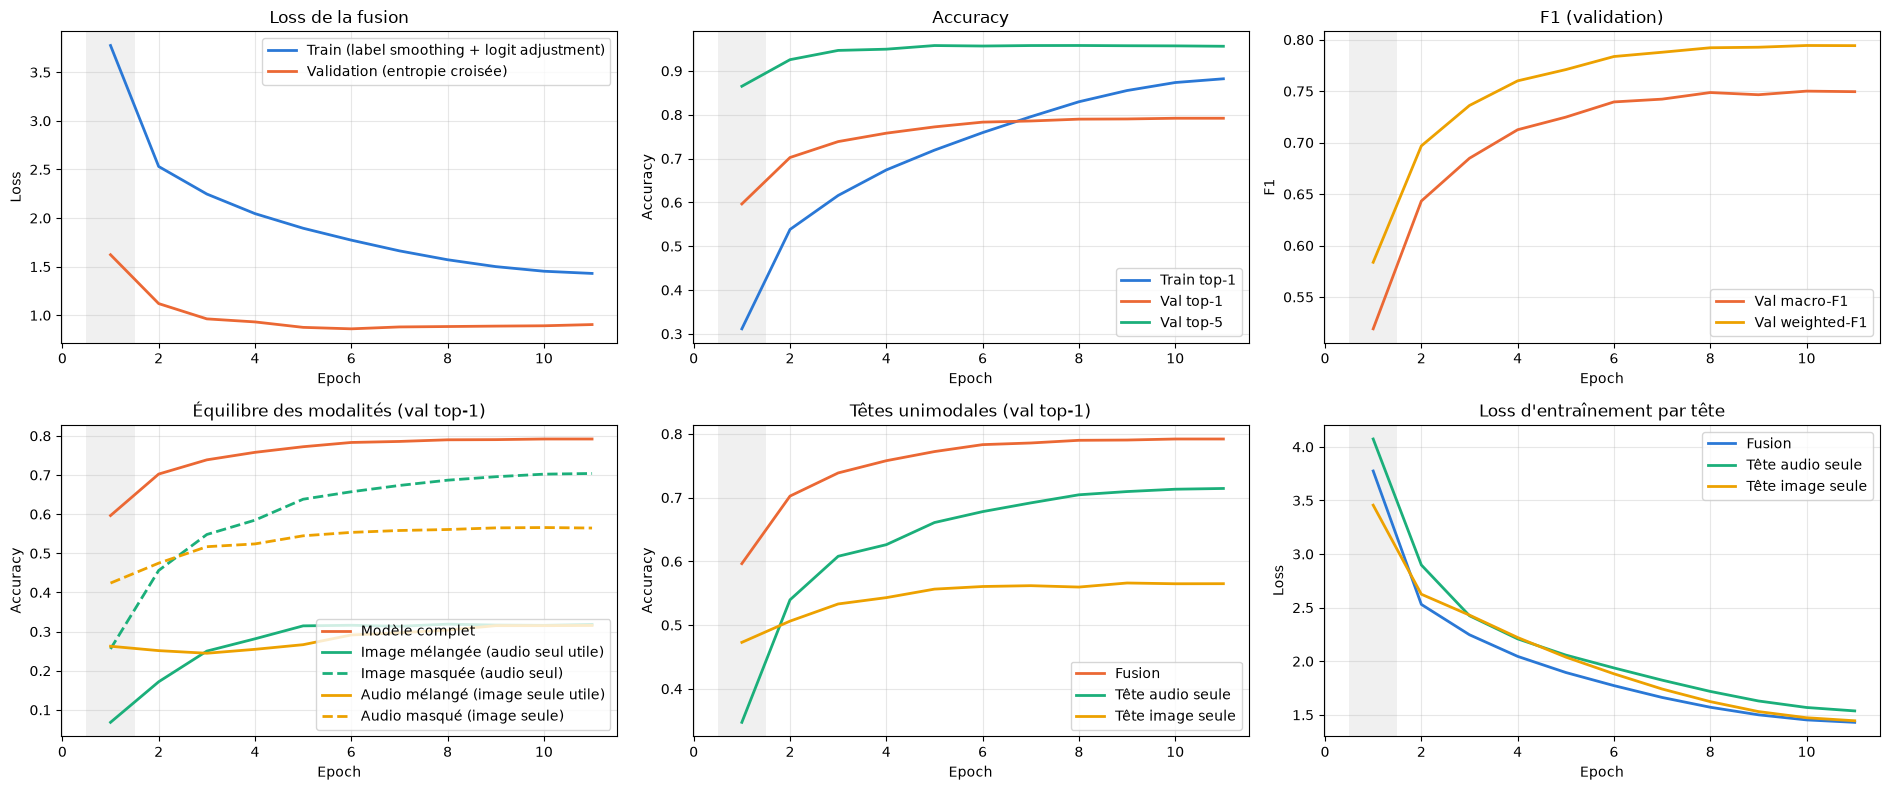

In [55]:
# Courbes d'apprentissage. Couleurs catégorielles dans un ordre fixe, même couleur = même rôle d'un
# graphique à l'autre : train en bleu, val (et fusion) en orange ; dans les graphiques des modalités
# et des têtes, ce qui relève de l'audio seul en vert, de l'image seule en jaune. Un seul axe par graphique.
from matplotlib.ticker import MaxNLocator

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(2, 3, figsize=(19, 8))

axes[0, 0].plot(epochs, history["train_loss"], color=COLORS[0], lw=2, label="Train (label smoothing + logit adjustment)")
axes[0, 0].plot(epochs, history["val_loss"], color=COLORS[1], lw=2, label="Validation (entropie croisée)")
axes[0, 0].set_title("Loss de la fusion")
axes[0, 0].set_ylabel("Loss")

axes[0, 1].plot(epochs, history["train_top1"], color=COLORS[0], lw=2, label="Train top-1")
axes[0, 1].plot(epochs, history["val_top1"], color=COLORS[1], lw=2, label="Val top-1")
axes[0, 1].plot(epochs, history["val_top5"], color=COLORS[2], lw=2, label="Val top-5")
axes[0, 1].set_title("Accuracy")
axes[0, 1].set_ylabel("Accuracy")

axes[0, 2].plot(epochs, history["val_macro_f1"], color=COLORS[1], lw=2, label="Val macro-F1")
axes[0, 2].plot(epochs, history["val_weighted_f1"], color=COLORS[3], lw=2, label="Val weighted-F1")
axes[0, 2].set_title("F1 (validation)")
axes[0, 2].set_ylabel("F1")

# Trait plein : modalité mélangée (la tête s'appuie-t-elle dessus ?) ; tirets : modalité masquée
# (que sait faire la tête de l'autre modalité seule ?)
axes[1, 0].plot(epochs, history["val_top1"], color=COLORS[1], lw=2, label="Modèle complet")
axes[1, 0].plot(epochs, history["val_top1_image_shuffled"], color=COLORS[2], lw=2, label="Image mélangée (audio seul utile)")
axes[1, 0].plot(epochs, history["val_top1_image_masked"], color=COLORS[2], lw=2, ls="--", label="Image masquée (audio seul)")
axes[1, 0].plot(epochs, history["val_top1_audio_shuffled"], color=COLORS[3], lw=2, label="Audio mélangé (image seule utile)")
axes[1, 0].plot(epochs, history["val_top1_audio_masked"], color=COLORS[3], lw=2, ls="--", label="Audio masqué (image seule)")
axes[1, 0].set_title("Équilibre des modalités (val top-1)")
axes[1, 0].set_ylabel("Accuracy")

axes[1, 1].plot(epochs, history["val_top1"], color=COLORS[1], lw=2, label="Fusion")
axes[1, 1].plot(epochs, history["val_top1_audio_head"], color=COLORS[2], lw=2, label="Tête audio seule")
axes[1, 1].plot(epochs, history["val_top1_image_head"], color=COLORS[3], lw=2, label="Tête image seule")
axes[1, 1].set_title("Têtes unimodales (val top-1)")
axes[1, 1].set_ylabel("Accuracy")

axes[1, 2].plot(epochs, history["train_loss"], color=COLORS[0], lw=2, label="Fusion")
axes[1, 2].plot(epochs, history["train_loss_audio_head"], color=COLORS[2], lw=2, label="Tête audio seule")
axes[1, 2].plot(epochs, history["train_loss_image_head"], color=COLORS[3], lw=2, label="Tête image seule")
axes[1, 2].set_title("Loss d'entraînement par tête")
axes[1, 2].set_ylabel("Loss")

for ax in axes.flat:
    # Zone grisée : époque(s) de gel des troncs pré-entraînés
    ax.axvspan(0.5, FREEZE_EPOCHS + 0.5, color="#000000", alpha=0.06, lw=0)
    ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))     # graduations sur des époques entières
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# **Évaluation finale sur le jeu de test**

Poids retenus sur le meilleur macro-F1 de validation. Le jeu de test (15 446 clips, ~50 par classe) n'a servi à aucun choix : ni hyperparamètres, ni sélection d'époque.

In [56]:
best_model = MultimodalClassifier(**MODEL_CONFIG, pretrained=False).to(device, memory_format=torch.channels_last)
best_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))

test_metrics = evaluate(best_model, test_loader, return_logits=True)

print(f"Test ({len(test_dataset)} clips)")
print(f"  top-1 accuracy : {test_metrics['top1']:.4f}")
print(f"  top-5 accuracy : {test_metrics['top5']:.4f}")
print(f"  macro-F1       : {test_metrics['macro_f1']:.4f}")
print(f"  weighted-F1    : {test_metrics['weighted_f1']:.4f}")
print(f"  loss           : {test_metrics['loss']:.4f}")
print("Équilibre des modalités :")
print(f"  image mélangée : top-1 {test_metrics['top1_image_shuffled']:.4f} | macro-F1 {test_metrics['macro_f1_image_shuffled']:.4f}")
print(f"  audio mélangé  : top-1 {test_metrics['top1_audio_shuffled']:.4f} | macro-F1 {test_metrics['macro_f1_audio_shuffled']:.4f}")
print(f"  image masquée  : top-1 {test_metrics['top1_image_masked']:.4f} | macro-F1 {test_metrics['macro_f1_image_masked']:.4f}")
print(f"  audio masqué   : top-1 {test_metrics['top1_audio_masked']:.4f} | macro-F1 {test_metrics['macro_f1_audio_masked']:.4f}")
print("Têtes unimodales (diagnostic, non utilisées pour la prédiction) :")
print(f"  image seule    : top-1 {test_metrics['top1_image_head']:.4f} | macro-F1 {test_metrics['macro_f1_image_head']:.4f}")
print(f"  audio seul     : top-1 {test_metrics['top1_audio_head']:.4f} | macro-F1 {test_metrics['macro_f1_audio_head']:.4f}")

# Classes les mieux et les moins bien reconnues (F1 par classe)
per_class = pd.Series(test_metrics["per_class_f1"].numpy(), index=CLASSES).sort_values()
print("\n10 classes les moins bien reconnues :")
print(per_class.head(10).round(3).to_string())
print("\n10 classes les mieux reconnues :")
print(per_class.tail(10).round(3).to_string())

Test (15446 clips)
  top-1 accuracy : 0.6154
  top-5 accuracy : 0.8294
  macro-F1       : 0.6098
  weighted-F1    : 0.6098
  loss           : 1.7802
Équilibre des modalités :
  image mélangée : top-1 0.2382 | macro-F1 0.2350
  audio mélangé  : top-1 0.2623 | macro-F1 0.2589
  image masquée  : top-1 0.5031 | macro-F1 0.4944
  audio masqué   : top-1 0.4299 | macro-F1 0.4259
Têtes unimodales (diagnostic, non utilisées pour la prédiction) :
  image seule    : top-1 0.4309 | macro-F1 0.4320
  audio seul     : top-1 0.5188 | macro-F1 0.5119

10 classes les moins bien reconnues :
baby babbling                0.025
bird chirping, tweeting      0.044
bird squawking               0.063
fire crackling               0.066
people battle cry            0.083
male speech, man speaking    0.096
wind rustling leaves         0.111
dog whimpering               0.148
mouse squeaking              0.158
playing timpani              0.159

10 classes les mieux reconnues :
slot machine            0.932
playin

# **Test corrigé : étiquettes VGGSounder**

Le test officiel de VGGSound contient des étiquettes fausses. D'après une ré-annotation humaine, environ 21 % des clips de test ne contiennent ni le son ni l'objet de leur étiquette : par exemple, les clips « fire crackling » montrent un carton qu'on déchire, une chorale ou un tracteur. L'erreur vient du CSV officiel d'Oxford, pas du pré-traitement (étiquettes vérifiées identiques).

**VGGSounder** (Zverev et al., ICCV 2025, *VGGSounder: Audio-Visual Evaluations for Foundation Models*) ré-annote le test en **multi-label** : chaque clip reçoit toutes les classes présentes, avec leur modalité (audible `A`, visible `V`, les deux `AV`). Fichier : `data/vggsounder_test_labels.csv`, copie de `vggsounder+background-music.csv` de la v1.0 (github.com/Bizilizi/VGGSounder, commit `5a91bf6` du 30/06/2026, licence Apache 2.0). Il couvre 15 069 de nos 15 446 clips de test, y compris ceux avec musique de fond (que le package `vggsounder` exclut par défaut).

Deux métriques corrigées, en plus des métriques d'origine (gardées pour comparer avec la littérature) :
- **hit@k multi-label** (métrique de VGGSounder) : la prédiction est juste si l'une des k premières classes prédites est présente dans le clip. Prédire « female singing » sur un clip « singing choir » où une femme chante n'est plus compté comme une erreur.
- **étiquette confirmée** : top-1, top-5 et macro-F1 habituels, restreints aux clips dont l'étiquette d'origine est confirmée par VGGSounder. Certaines classes n'y gardent presque aucun clip (« baby babbling » : 1), leur F1 y est donc très bruité.

Seul le test est ré-annoté : train et val gardent le bruit d'étiquetage d'origine de VGGSound.

In [67]:
# Étiquettes VGGSounder : une ligne par (clip, classe présente dans le clip)
VGGSOUNDER_CSV = os.path.join(DATA_DIR, "vggsounder_test_labels.csv")
vggsounder = pd.read_csv(VGGSOUNDER_CSV)

# Matrice multi-hot (clips de test x classes), dans l'ordre de test_df, qui est celui de test_loader
row_of_clip = {clip_id: i for i, clip_id in enumerate(test_df["clip_id"])}
present = torch.zeros(len(test_df), NUM_CLASSES, dtype=torch.bool)
present[vggsounder["video_id"].map(row_of_clip).to_numpy(), vggsounder["label"].map(CLASS_TO_IDX).to_numpy()] = True
annotated = present.any(dim=1)                                  # clips ré-annotés par VGGSounder

test_logits = test_metrics["logits"]
test_targets = torch.tensor(test_df["label"].map(CLASS_TO_IDX).to_numpy())

# hit@k multi-label : au moins une des k premières prédictions est présente dans le clip
top5_predictions = test_logits[annotated].topk(5, dim=1).indices
hits = present[annotated].gather(1, top5_predictions)          # (N, 5) : j-ième prédiction présente ?
hit1 = hits[:, 0].float().mean().item()
hit5 = hits.any(dim=1).float().mean().item()

# Métriques mono-label sur les seuls clips dont l'étiquette d'origine est confirmée
confirmed = present[torch.arange(len(test_df)), test_targets]
confirmed_metrics = compute_metrics(test_logits[confirmed], test_targets[confirmed], NUM_CLASSES)

print(f"Test corrigé avec VGGSounder ({annotated.sum().item()} clips ré-annotés sur {len(test_df)})")
print(f"  multi-label          : hit@1 {hit1:.4f} | hit@5 {hit5:.4f}")
print(f"  étiquette confirmée  : top-1 {confirmed_metrics['top1']:.4f} | top-5 {confirmed_metrics['top5']:.4f} | "
      f"macro-F1 {confirmed_metrics['macro_f1']:.4f} ({confirmed.sum().item()} clips)")
print(f"  étiquettes d'origine : top-1 {test_metrics['top1']:.4f} | top-5 {test_metrics['top5']:.4f} | "
      f"macro-F1 {test_metrics['macro_f1']:.4f} (rappel)")

# Classes dont l'étiquette d'origine est le moins souvent confirmée : sur le test d'origine, leur
# F1 mesure surtout le bruit d'étiquetage
confirmation_rate = pd.Series(confirmed.numpy(), index=test_df["label"])[annotated.numpy()].groupby(level=0).mean()
print("\nTaux de confirmation de l'étiquette d'origine, 10 classes les plus touchées :")
print(confirmation_rate.sort_values().head(10).round(2).to_string())

Test corrigé avec VGGSounder (15069 clips ré-annotés sur 15446)
  multi-label          : hit@1 0.6688 | hit@5 0.8486
  étiquette confirmée  : top-1 0.6822 | top-5 0.8755 | macro-F1 0.6615 (11905 clips)
  étiquettes d'origine : top-1 0.6154 | top-5 0.8294 | macro-F1 0.6098 (rappel)

Taux de confirmation de l'étiquette d'origine, 10 classes les plus touchées :
label
baby babbling           0.02
fire crackling          0.07
running electric fan    0.13
people humming          0.14
eating with cutlery     0.19
firing muskets          0.19
cell phone buzzing      0.20
dog whimpering          0.22
mynah bird singing      0.26
people battle cry       0.27


Clip aKZ3NJi8GVU_000000 (indice 10148 de test_df)
  étiquette d'origine : baltimore oriole calling
  VGGSounder          : baltimore oriole calling [AV], bird chirping, tweeting [AV], wind noise [AV], wind rustling leaves [AV]


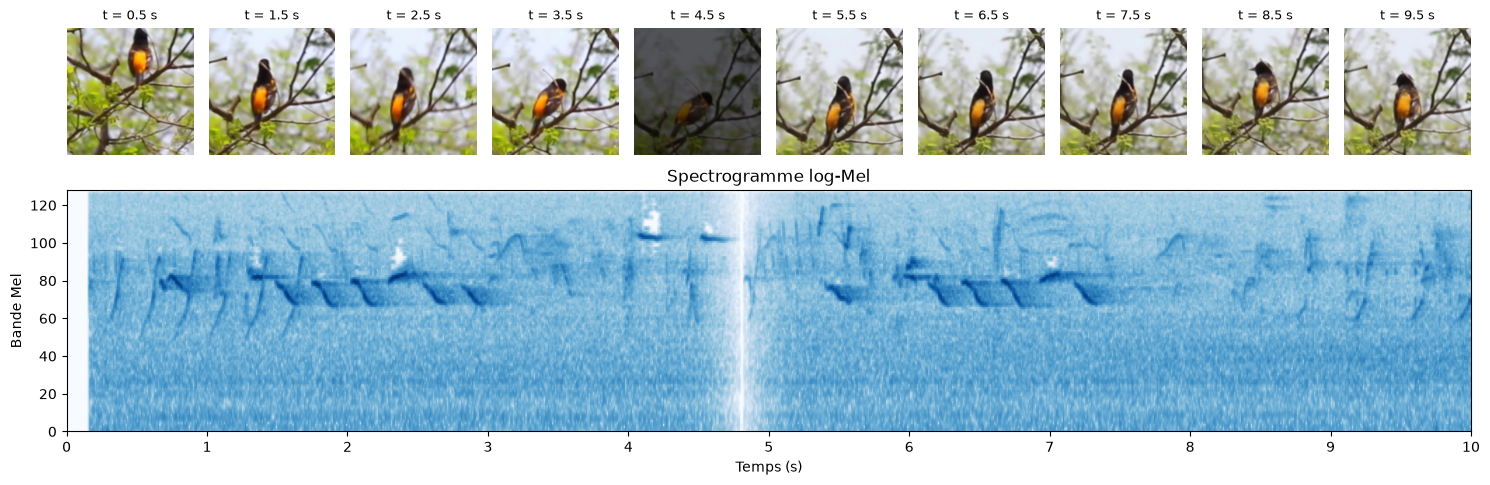

Top-5 (✓ : étiquette d'origine ; ★ : présente d'après VGGSounder)


,fusion,"fusion, audio masqué",tête image seule,tête audio seule
rang,,,,
1,baltimore oriole calling (99.5%) ✓★,baltimore oriole calling (98.8%) ✓★,baltimore oriole calling (99.9%) ✓★,baltimore oriole calling (81.6%) ✓★
2,bird squawking (0.1%),black capped chickadee calling (0.1%),cat caterwauling (0.0%),wood thrush calling (5.2%)
3,"bird chirping, tweeting (0.1%) ★","bee, wasp, etc. buzzing (0.1%)","playing violin, fiddle (0.0%)","bird chirping, tweeting (4.1%) ★"
4,mynah bird singing (0.0%),"playing violin, fiddle (0.0%)",bird squawking (0.0%),mynah bird singing (3.2%)
5,wood thrush calling (0.0%),bird squawking (0.0%),playing castanets (0.0%),bird squawking (2.5%)


In [82]:
# Tests individuels sur le jeu de test : un clip à la fois, avec les 10 images vues par le modèle, le
# spectrogramme, un lecteur audio, les étiquettes (d'origine et VGGSounder) et le top-5 de chaque tête
# (dont la fusion avec l'audio masqué : ce que la tête de fusion tire de l'image seule).
# Relancer la cellule tire un nouveau clip ; modifier l'appel en bas de cellule pour en choisir un.
from IPython.display import Audio, display

# Meilleur modèle : celui de l'évaluation finale s'il est déjà chargé, sinon chargé ici
if "best_model" not in globals():
    best_model = MultimodalClassifier(**MODEL_CONFIG, pretrained=False).to(device, memory_format=torch.channels_last)
    best_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
best_model.eval()

vggsounder_test = pd.read_csv(os.path.join(DATA_DIR, "vggsounder_test_labels.csv"))


def show_test_clip(clip=None, label=None, only_errors=False):
    # clip : None (tirage au hasard), indice dans test_df, ou identifiant de clip ("abc_000030").
    # label : tirage restreint à une classe (étiquette d'origine).
    # only_errors : tirage restreint aux clips mal classés par la fusion (évaluation finale requise).
    if clip is None:
        candidates = np.arange(len(test_df))
        if label is not None:
            assert label in CLASS_TO_IDX, f"classe inconnue : {label!r}"
            candidates = candidates[(test_df["label"] == label).to_numpy()]
        if only_errors:
            assert "test_metrics" in globals(), "only_errors : exécuter d'abord la cellule d'évaluation finale"
            wrong = test_metrics["logits"].argmax(dim=1).numpy() != test_df["label"].map(CLASS_TO_IDX).to_numpy()
            candidates = candidates[wrong[candidates]]
        assert len(candidates) > 0, "aucun clip ne correspond à ces critères"
        index = int(random.choice(candidates))
    elif isinstance(clip, str):
        matches = np.flatnonzero(test_df["clip_id"].to_numpy() == clip)
        assert len(matches) == 1, f"clip absent du jeu de test : {clip!r}"
        index = int(matches[0])
    else:
        index = int(clip)

    # Même traitement que evaluate : les FRAMES_PER_CLIP images du clip, features moyennées sur T
    images, waveform, target = test_dataset[index]                # images (T, 3, 224, 224) uint8
    clip_id = test_df.at[index, "clip_id"]
    with torch.no_grad(), torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        image_input, waveform_input, _ = to_device(images[None], waveform[None], torch.tensor([target]))
        image_features, audio_features = best_model.encode(image_input, waveform_input)   # (1, E), (1, E)
        logits = {
            "fusion": best_model.classify(image_features, audio_features),
            "fusion, audio masqué": best_model.classify(image_features, torch.zeros_like(audio_features)),
            "tête image seule": best_model.image_aux_head(image_features),
            "tête audio seule": best_model.audio_aux_head(audio_features),
        }

    # Étiquettes
    vgg_rows = vggsounder_test[vggsounder_test["video_id"] == clip_id]
    print(f"Clip {clip_id} (indice {index} de test_df)")
    print(f"  étiquette d'origine : {CLASSES[target]}")
    if len(vgg_rows):
        meta = [name for name in ("background_music", "voice_over", "static_image") if vgg_rows[name].iloc[0]]
        print(f"  VGGSounder          : " + ", ".join(f"{l} [{m}]" for l, m in zip(vgg_rows["label"], vgg_rows["modality"]))
              + (f"  (méta : {', '.join(meta)})" if meta else ""))
    else:
        print("  VGGSounder          : clip non ré-annoté")

    # Les images vues par le modèle (après redimensionnement et crop centré), au-dessus du
    # spectrogramme : l'image k, prise au milieu de la seconde [k, k+1), est au-dessus de cette seconde.
    # Clip de moins de 10 images : certaines sont répétées (même instant dans le titre).
    frame_indices = test_dataset._frame_indices(test_dataset.n_frames[index])
    fig, axes = plt.subplot_mosaic([[f"image{k}" for k in range(FRAMES_PER_CLIP)], ["mel"] * FRAMES_PER_CLIP],
                                   figsize=(15, 5), gridspec_kw={"height_ratios": [1, 1.4]})
    for k, frame_index in enumerate(frame_indices):
        axes[f"image{k}"].imshow(images[k].permute(1, 2, 0).numpy())
        axes[f"image{k}"].set_title(f"t = {frame_index + 0.5:.1f} s", fontsize=9)
        axes[f"image{k}"].axis("off")
    logmel = LogMelSpectrogram()(waveform[None])[0, 0]
    axes["mel"].imshow(logmel.numpy(), origin="lower", aspect="auto", cmap="Blues", extent=[0, CLIP_SECONDS, 0, N_MELS])
    axes["mel"].set_xticks(range(CLIP_SECONDS + 1))
    axes["mel"].set_xlabel("Temps (s)")
    axes["mel"].set_ylabel("Bande Mel")
    axes["mel"].set_title("Spectrogramme log-Mel")
    plt.tight_layout()
    plt.show()

    # normalize=False : le clip est joué à son niveau d'origine
    display(Audio(waveform.numpy().astype(np.float32) / 32768, rate=SAMPLE_RATE, normalize=False))

    # Top-5 de chaque tête. ✓ : étiquette d'origine ; ★ : classe présente d'après VGGSounder.
    vgg_labels = set(vgg_rows["label"])
    def describe(class_index, probability):
        name = CLASSES[class_index]
        marks = ("✓" if class_index == target else "") + ("★" if name in vgg_labels else "")
        return f"{name} ({probability:.1%}) {marks}".rstrip()

    top5 = {}
    for name, head_logits in logits.items():
        probabilities, class_indices = head_logits[0].float().softmax(dim=0).topk(5)
        top5[name] = [describe(i, p) for p, i in zip(probabilities.tolist(), class_indices.tolist())]
    print("Top-5 (✓ : étiquette d'origine ; ★ : présente d'après VGGSounder)")
    display(pd.DataFrame(top5, index=pd.RangeIndex(1, 6, name="rang")))


show_test_clip()                               # clip tiré au hasard
# show_test_clip(1234)                         # indice dans test_df
# show_test_clip("-0yRK50zyTI_000030")         # identifiant de clip
# show_test_clip(label="playing tennis")       # au hasard dans une classe
# show_test_clip(only_errors=True)             # au hasard parmi les erreurs de la fusion